# CM laser: static and space-charge distortion corrections with PHGarfield, step by step

**Data.** CM laser clusters (LaserPadAggregator + LaserAggregatedClusterizer):
- beam runs 79508, 79513, 79516, 79529 (low luminosity, I_side ≈ 1.8–2.9 µA) and 80892, 81558 (≈ 5.4–7 µA),
  in 100-segment blocks 0 / 1000 / 2000 (17 blocks);
- no-beam field-on runs 75073 (before the IFC voltage change) and 83319 (after);
- the field-off run 78242.

**Method.** Every cluster is drift-corrected with PHGarfield (reverse drift through E and B). The static part covers
the field cage, the module frames and E×B with the TPC placement; the space-charge part is a 3D map × keff. The
corrected clusters are compared with:
- the CM truth pattern (matcher);
- the field-off run (robust matching: the radial offset per ring is removed before matching);
- the no-beam run, cluster to cluster (the static part cancels).

**Final configuration.** α 2.0 map, TPC z −40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad (survey x / y), IFC automatic,
frame −180, P/T-corrected CM field per block. keff = b × I_side, where I_side is the all-module median GEM current of
the side (TPC_CONDITIONS SOUTH / NORTH); b ≈ 0.84 for 795xx (joint absolute fit with the vertex-constrained sagitta)
and ≈ 0.70 for 80892 / 81558. Each keff point is
interpolated cluster by cluster between the absolute-keff scan points (`make_v2_data.py`).

**Sagitta.** It is taken from the slope of Δφ(R): 5290 µm per mrad/cm, i.e. 100 µm ≈ 0.7 mrad over 33–71 cm. This is
RΔφ = c1R + c2R², a line through R = 0 (absorbed) plus curvature, which is what a vertex- or silicon-constrained track
sees. The free quadratic c0 + c1R + c2R² is not robust over 33–71 cm: c0 and c2 are strongly correlated, and the R1
structure decides the split (dropping the R1 rings flips its sign). It is shown only as a backup.

**Conventions.** Residual = target − reference; RΔφ and dR in mm, Δφ = RΔφ/R in mrad; R rings of 3.75 cm (33–71 cm).
The R profiles are shown in **Δφ**: a flat Δφ(R) is a rotation, which a track absorbs. RΔφ(R) of a rotation is a
straight line through 0; the DCA (constant RΔφ) and the curvature (sagitta) are what a track keeps. Dotted lines are
the R1 / R2 / R3 module boundaries. DCA = constant term of the quadratic ring fit at R = 0; sagitta = quadratic term
over 30–76 cm (100 µm ≈ 0.009 / GeV in q/pT at 1.4 T).

**Slides.** `pdf_v2/CM_laser_deck.pdf` has every section with its backup figures; `pdf_v2/CM_laser_deck_main.pdf`
has the main figures only; `pdf_v2/<section>.pdf` and `pdf_v2/runs/run_<run>.pdf` are the detailed backups
(`python3 make_deck_v2.py`).

In [1]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
import v2plots as v, cmplots as c, absplots as ap
plt.rcParams['figure.dpi'] = 72
def show(figs):
    for f in figs:
        display(f)
    plt.close('all')

## 0. Configuration and keff per block
keff per block in the final configuration against the side GEM current. Open markers are the CDB keff of the run, the
old recipe: 1.55 × (0.815 I/I₇₉₅₁₃ + 0.185). The table gives b, keff per side, and the N/S keff ratio next to the N/S
current ratio. They are equal by construction: one b for both sides.

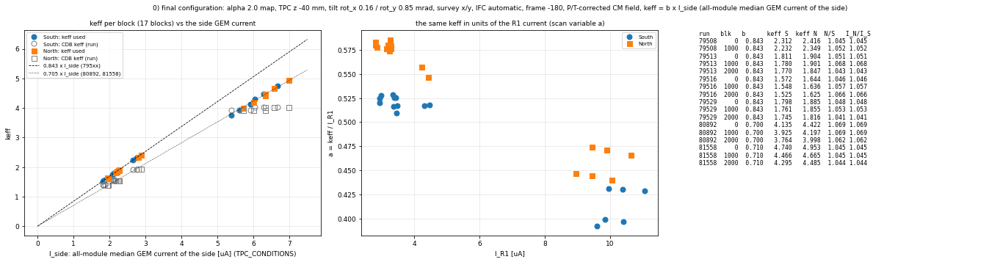

79508 block    0: b 0.8425  keff South 2.312  North 2.416
79508 block 1000: b 0.8425  keff South 2.232  North 2.349
79513 block    0: b 0.8425  keff South 1.811  North 1.904
79513 block 1000: b 0.8425  keff South 1.780  North 1.901
79513 block 2000: b 0.8425  keff South 1.770  North 1.847
79516 block    0: b 0.8425  keff South 1.572  North 1.644
79516 block 1000: b 0.8425  keff South 1.548  North 1.636
79516 block 2000: b 0.8425  keff South 1.525  North 1.625
79529 block    0: b 0.8425  keff South 1.798  North 1.885
79529 block 1000: b 0.8425  keff South 1.761  North 1.855
79529 block 2000: b 0.8425  keff South 1.745  North 1.816
80892 block    0: b 0.7000  keff South 4.135  North 4.422
80892 block 1000: b 0.7000  keff South 3.925  North 4.197
80892 block 2000: b 0.7000  keff South 3.764  North 3.998
81558 block    0: b 0.7100  keff South 4.740  North 4.953
81558 block 1000: b 0.7100  keff South 4.466  North 4.665
81558 block 2000: b 0.7100  keff South 4.295  North 4.485


In [2]:
m, e = v.sec_overview(); show(m)
for r in v.final_keff(): print(f"{r['run']} block {r['blk']:4d}: b {r['b']:.4f}  keff South {r['kS']:.3f}  North {r['kN']:.3f}")

## 1. What has to be corrected
Before any correction:
- **Beam vs CM truth:** about +20 mm RΔφ at R = 0 at low luminosity and about +40 mm at high luminosity, with a
  large curvature. This includes the static part.
- **Beam − no beam:** the space charge alone.
- **No beam, field on − field off:** the static field-on distortion (E×B in the field cage and frames, TPC placement).
- **Field off vs truth:** the drift-model-free reference.

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/v2plots.py:198: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(2, 4, figsize=(24, 9))


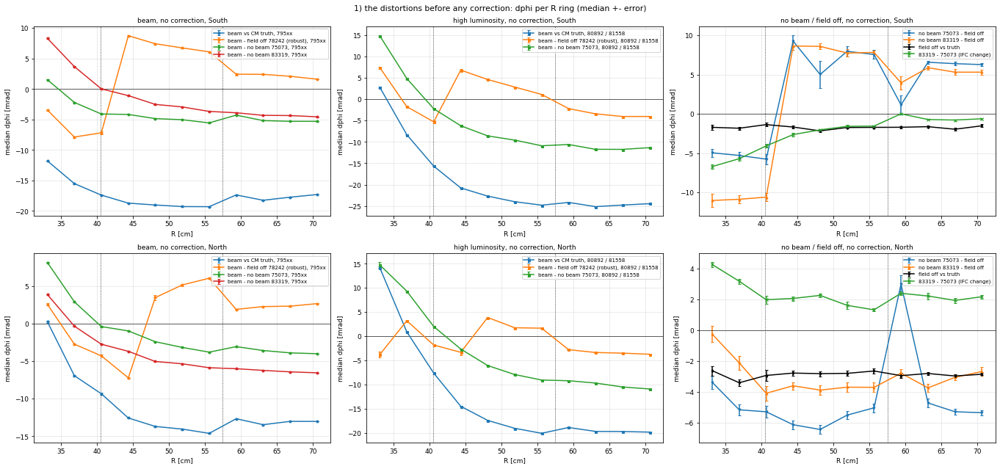

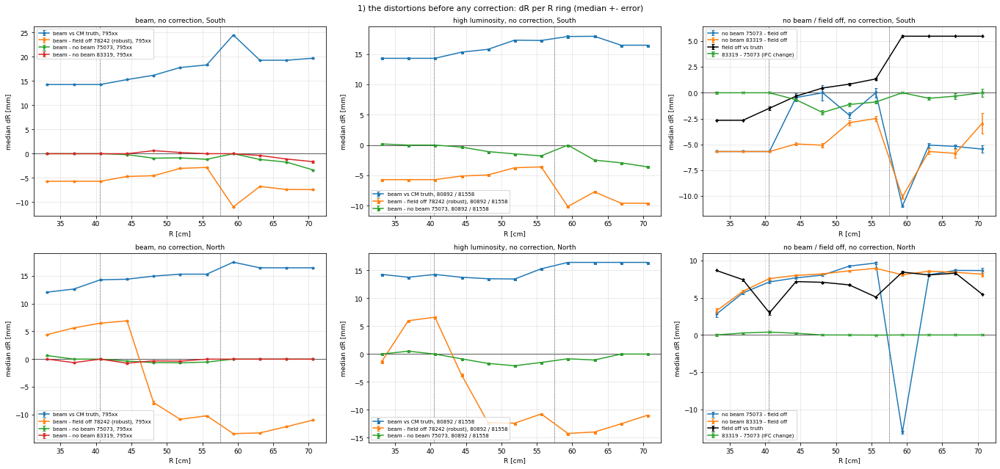

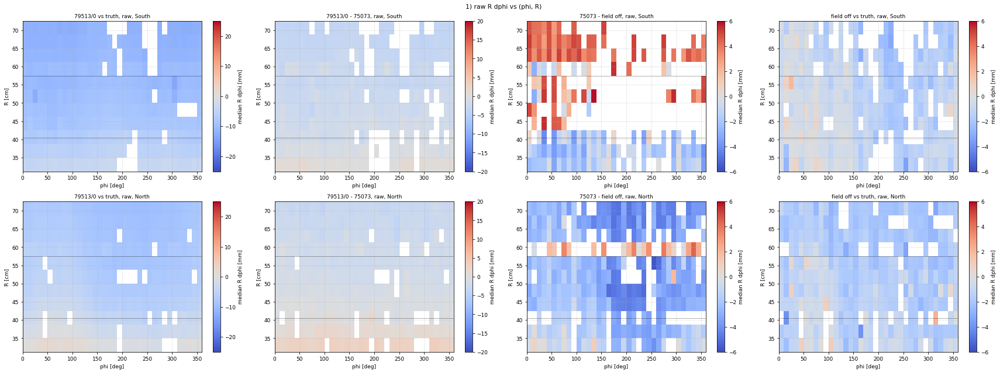

raw beam vs CM truth                 South: 795xx DCA +14.16 mm sag    -96 um | high lumi DCA +39.27 mm sag  -1537 um
raw beam vs CM truth                 North: 795xx DCA +22.36 mm sag   -646 um | high lumi DCA +49.88 mm sag  -2126 um
raw beam - field off 78242 (robust)  South: 795xx DCA -35.09 mm sag   +362 um | high lumi DCA -14.09 mm sag  -1389 um
raw beam - field off 78242 (robust)  North: 795xx DCA  -2.10 mm sag   +878 um | high lumi DCA -11.48 mm sag  -1179 um
raw beam - no beam 75073             South: 795xx DCA  +9.48 mm sag   -409 um | high lumi DCA +36.29 mm sag  -1851 um
raw beam - no beam 75073             North: 795xx DCA +16.27 mm sag   -874 um | high lumi DCA +35.27 mm sag  -1851 um


In [3]:
m, e = v.sec_raw(); show(m)
low, high = v.blocks_low_high()
for k in ('T', 'OFF', 'NB75'):
    for s in (0, 1):
        d1, s1 = v.fit_dca_sag(c.load_many(f'{k}_raw', low), s); d2, s2 = v.fit_dca_sag(c.load_many(f'{k}_raw', high), s)
        print(f"raw {v.CMP[k]:32s} {c.SIDES[s]:5s}: 795xx DCA {d1:+6.2f} mm sag {s1:+6.0f} um | high lumi DCA {d2:+6.2f} mm sag {s2:+6.0f} um")

## 2. Static distortions: tilt, z, IFC, CM field
The first three panels come from the static scan (earlier production, 380 V/cm; the static knobs do not depend on the
space-charge settings):
- **b) tilt:** the first harmonic (dx, dy). Four independent measurements give rot_x 0.16, rot_y 0.85 mrad.
- **c) z shift:** mostly the North sagitta and the North − South balance (field on − off, beam − field off).
- **d) IFC:** the 79513 IFC voltage scan, and 83319 − 75073 across the IFC change; then the frame charge and the CM
  field at the final geometry.

After that, the static stage of the final configuration (P/T field, z −40): no beam vs field off and vs truth, before
and after the static correction.

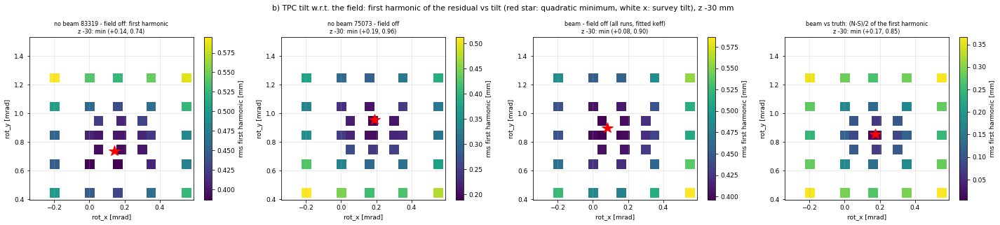

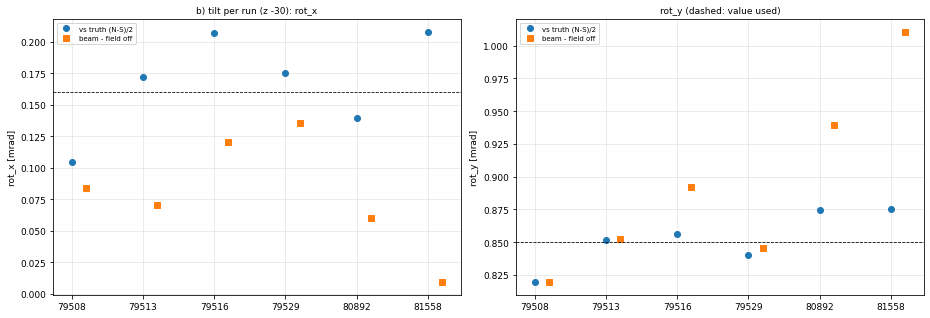

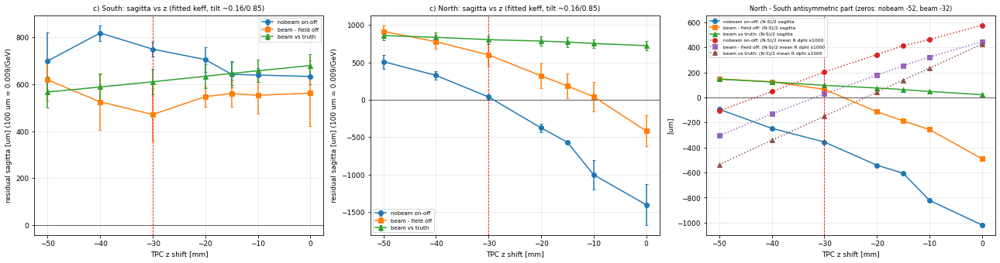

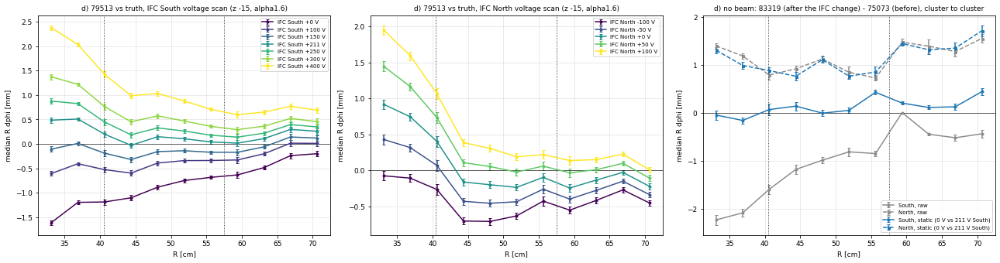

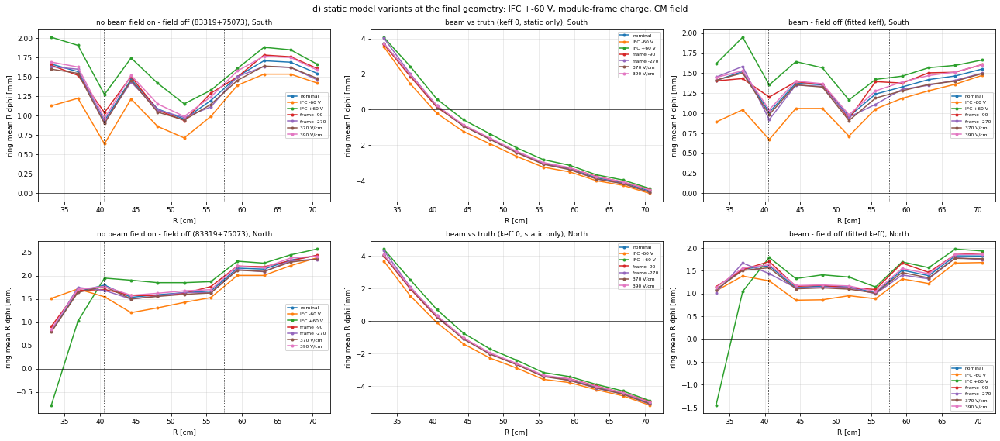

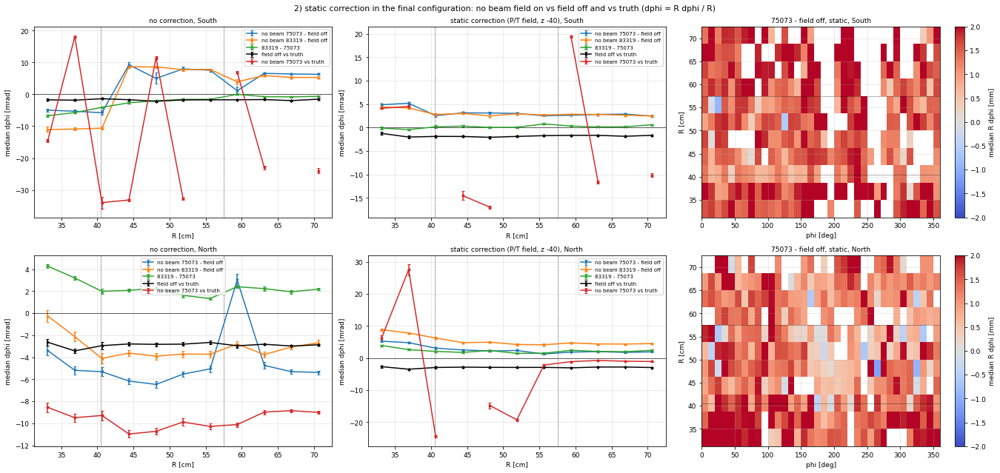

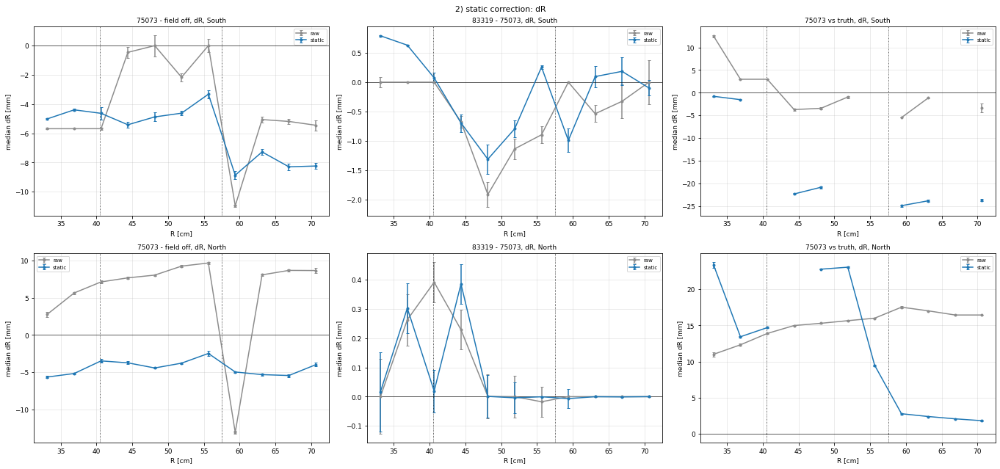

In [4]:
m, e = v.sec_static(); show(m)

## 3–5. Space-charge map shape, which GEM current, absolute keff
- **3. Why the space-charge-only keff is not enough:** beam − no beam cancels the static field-on curvature, but
  tracks feel it. The SC-only keff leaves several mm at R = 0.
- **α:** with the right radial profile, one keff zeroes both the DCA and the sagitta.
- **4. GEM current:** with the R1 currents, North needs about 10 % more keff per µA. With the all-module side
  currents, both sides take one coefficient.
- **5. Joint minimisation** over α, z and b (795xx, vs truth), then b per run. The high-luminosity runs want
  b ≈ 0.70 and a flatter profile (DCA alone wants ≈ 0.70, the sagitta ≈ 0.85).

The sagitta in the fit is the vertex-constrained one (Δφ slope). With the free quadratic, the fit gave b = 0.81; that
value was biased by the R1 structure.

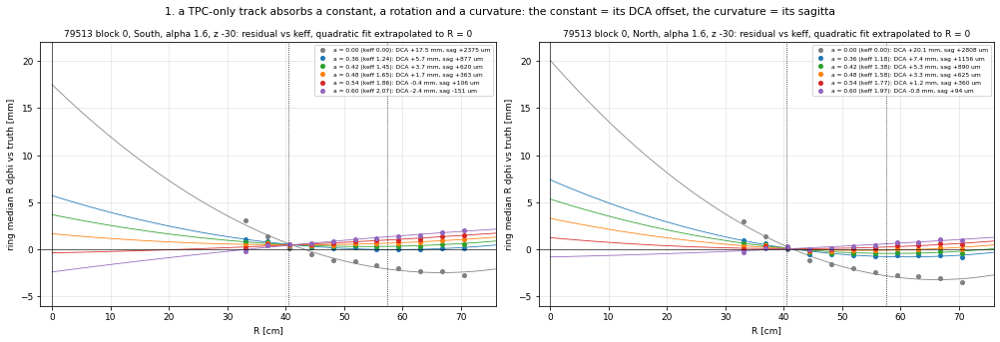

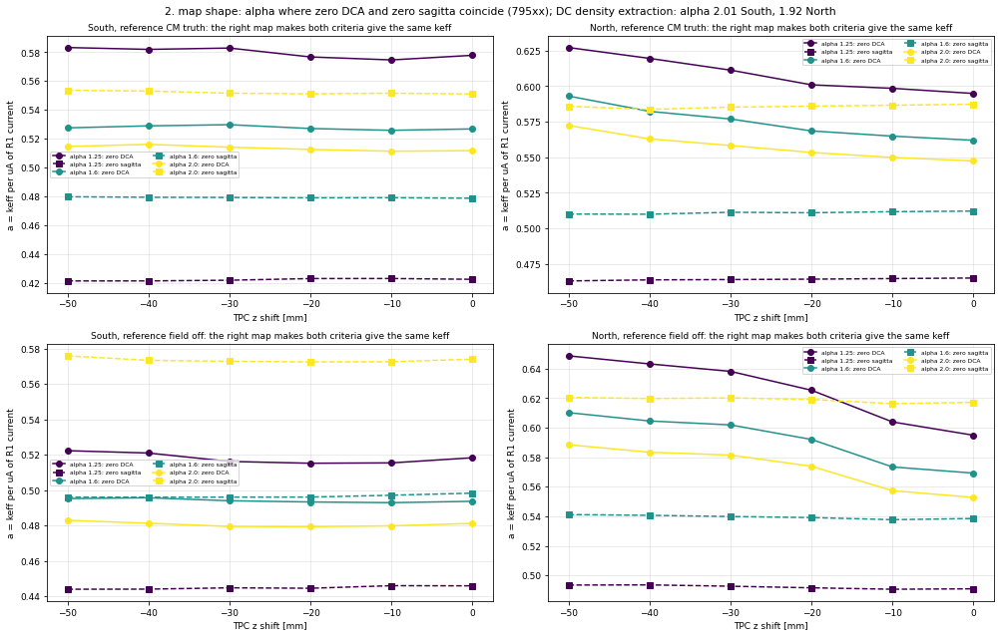

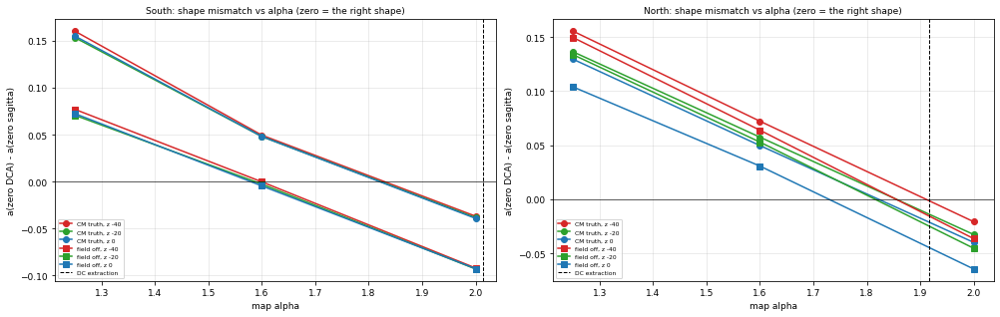

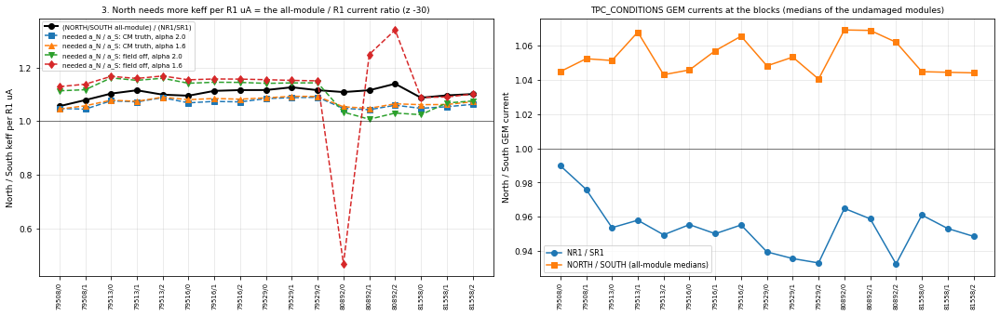

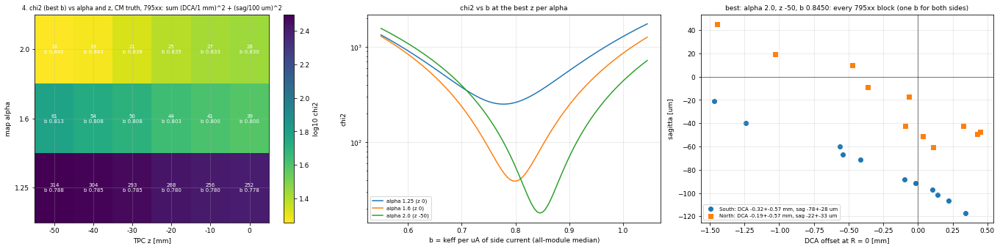

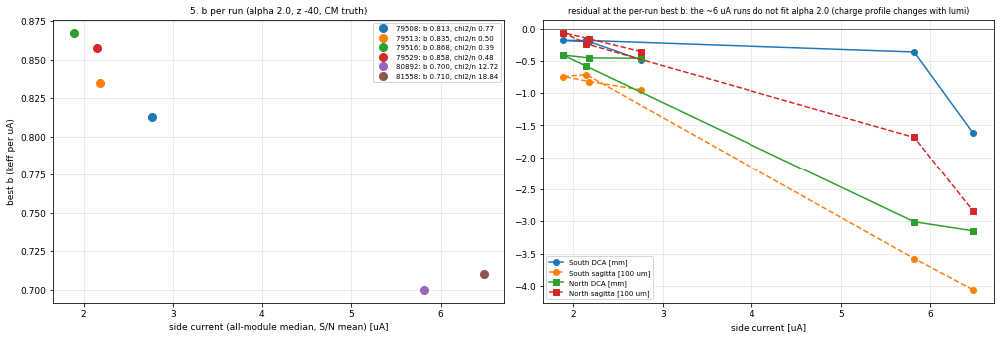

best (truth reference): [(18.1, 2.0, -50, 0.845), (18.9, 2.0, -40, 0.8425), (21.4, 2.0, -30, 0.8375), (24.6, 2.0, -20, 0.835), (26.7, 2.0, -10, 0.8325)]
field off as reference: [(13.6, 1.6, 0, 0.805), (16.2, 1.6, -10, 0.805), (26.1, 1.6, -20, 0.8125)]
R1 currents instead: (42.05461909190377, 2.0, -40, 0.5450000000000002)
  run 79508: best b 0.8125  chi2/n 0.77
  run 79513: best b 0.8350  chi2/n 0.50
  run 79516: best b 0.8675  chi2/n 0.39
  run 79529: best b 0.8575  chi2/n 0.48
  run 80892: best b 0.7000  chi2/n 12.72
  run 81558: best b 0.7100  chi2/n 18.84
  alpha estimate South vs field off z -40: 1.60
  alpha estimate South vs field off z -20: 1.59
  alpha estimate South vs field off z 0: 1.58
  alpha estimate South vs CM truth z -40: 1.83
  alpha estimate South vs CM truth z -20: 1.82
  alpha estimate South vs CM truth z 0: 1.82
  alpha estimate North vs field off z -40: 1.85
  alpha estimate North vs field off z -20: 1.82
  alpha estimate North vs field off z 0: 1.73
  alpha esti

In [5]:
m, e, info = v.sec_keff(); show(m)
print("best (truth reference):", [(round(r[0], 1), r[1], r[2], round(r[3], 4)) for r in info['best']])
print("field off as reference:", [(round(r[0], 1), r[1], r[2], round(r[3], 4)) for r in info['best_off']])
print("R1 currents instead:", info['bestR1'])
for run, b, chi in info['runs']: print(f"  run {run}: best b {b:.4f}  chi2/n {chi:.2f}")
for k, val in sorted(info['alpha'].items()): print(f"  alpha estimate {c.SIDES[k[0]]} vs {ap.REFS[k[1]]} z {k[2]}: {val[0]:.2f}{val[1]}")

## 6. Corrections step by step, against every reference
For each reference (truth, field off, no beam 75073, no beam 83319):
- Δφ = RΔφ/R per ring for no correction / static / static + space charge (flat = a rotation, harmless);
- the final stage with b × 0.97 / 1 / 1.03;
- dR per ring and all-cluster histograms;
- **the final stage per 30° φ sector**: Δφ, dR and RΔφ vs R, one curve per sector, black = all φ;
- maps vs (φ, R).

The backup (deck) adds:
- the same profiles in RΔφ;
- the per-sector pages for the static stage and for the high-luminosity runs;
- high luminosity with its own b and with the 795xx b;
- every block.

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/v2plots.py:292: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(2, 3, figsize=(19, 9))


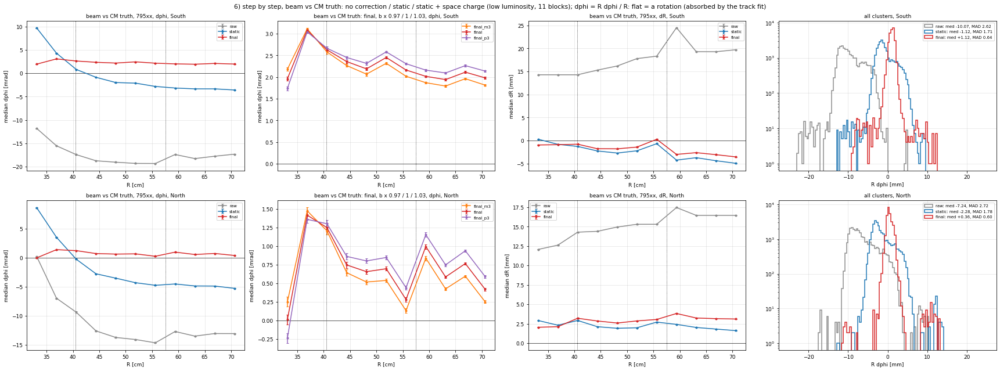

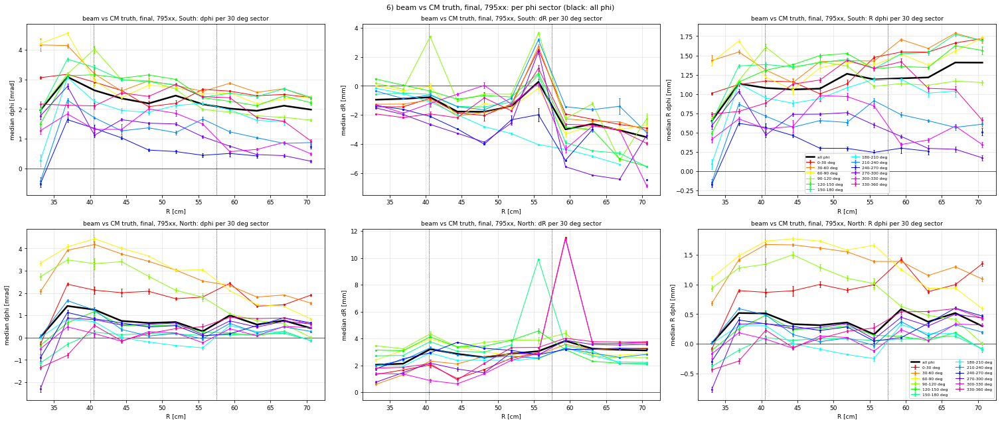

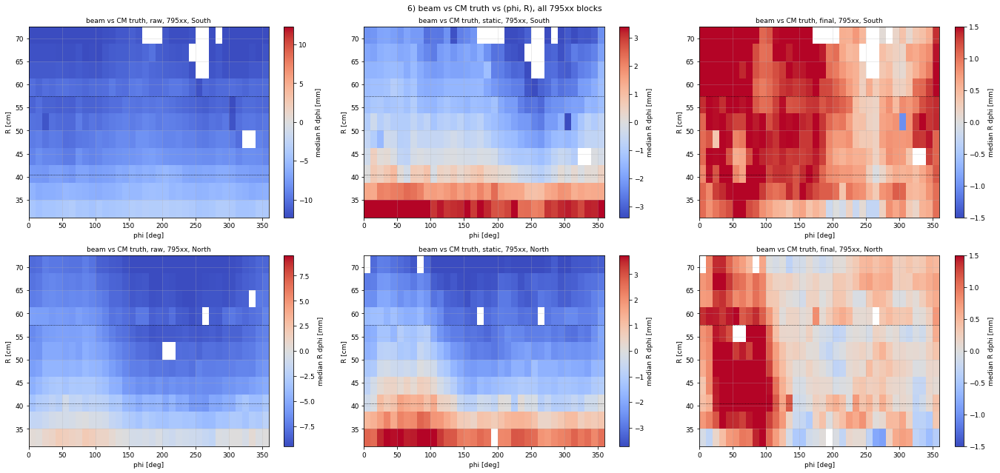

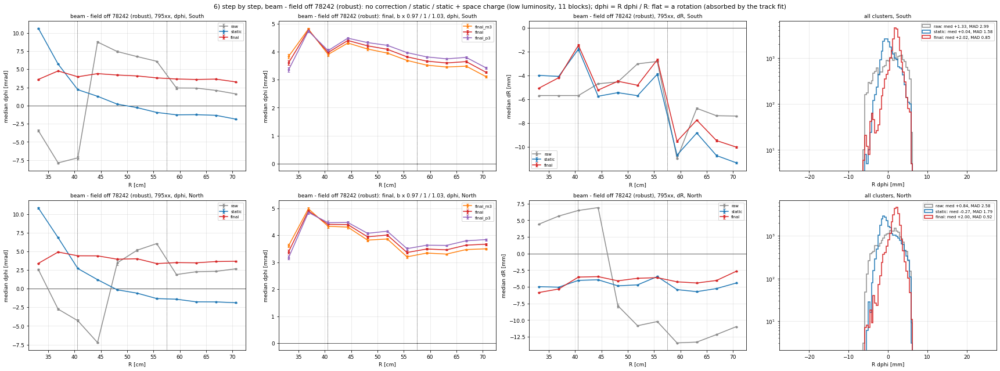

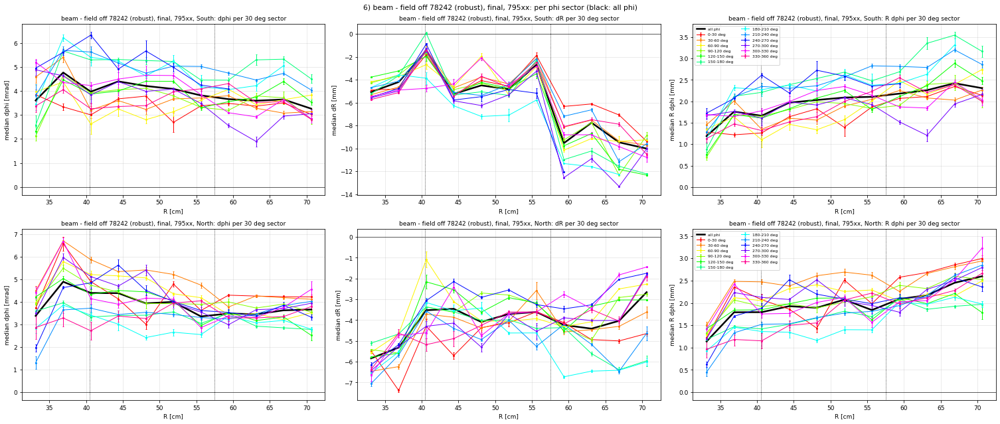

...

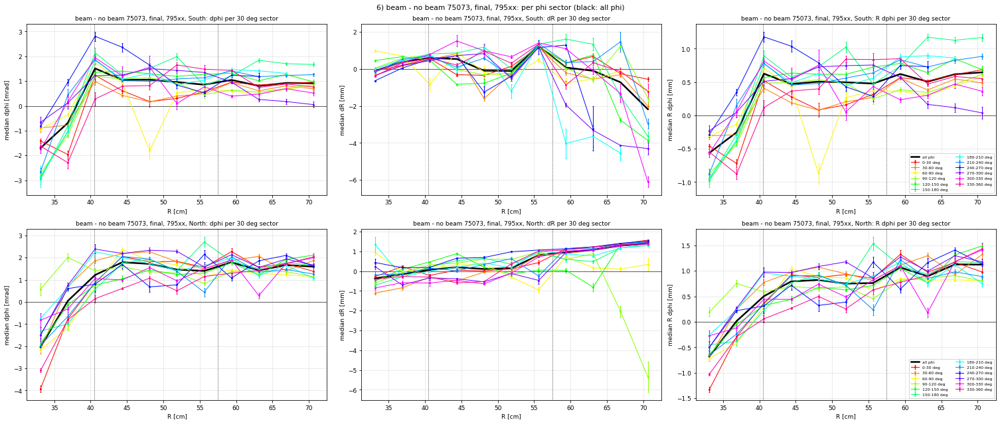

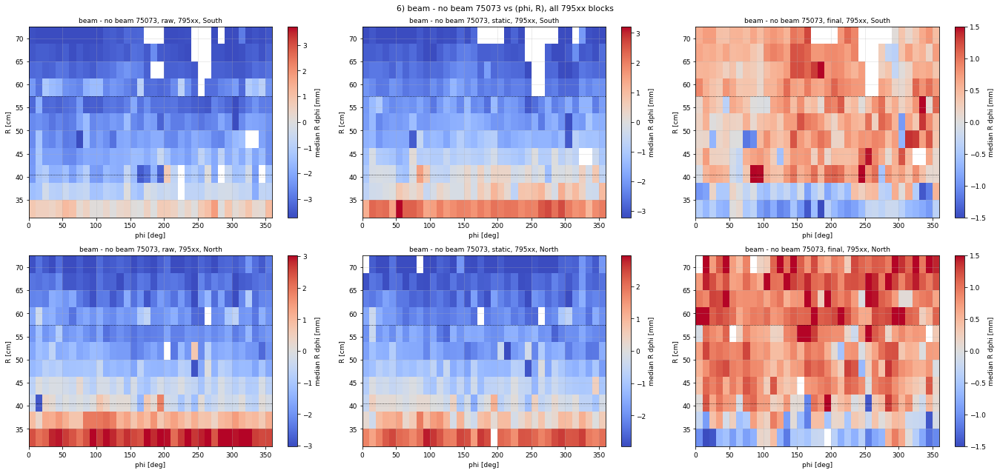

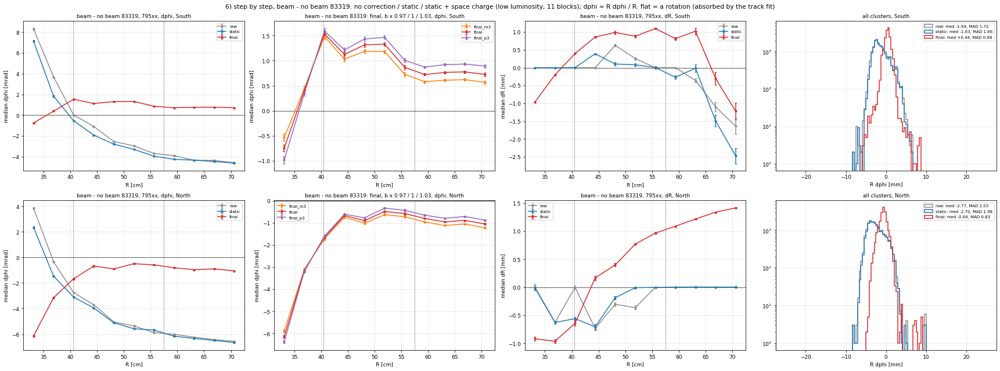

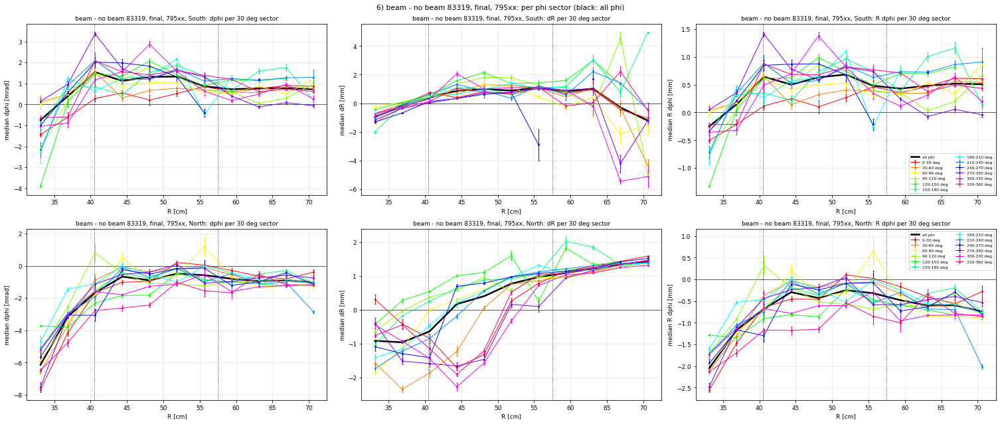

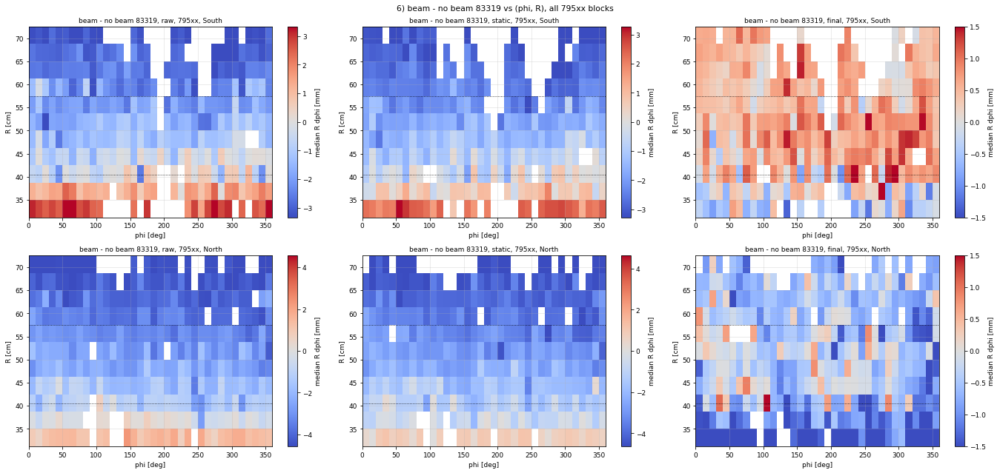

beam vs CM truth                 raw    : South median -10.07 MAD  2.62 mm  North median  -7.24 MAD  2.72 mm
beam vs CM truth                 static : South median  -1.12 MAD  1.71 mm  North median  -2.28 MAD  1.78 mm
beam vs CM truth                 final  : South median  +1.12 MAD  0.64 mm  North median  +0.36 MAD  0.60 mm
beam - field off 78242 (robust)  raw    : South median  +1.33 MAD  2.99 mm  North median  +0.84 MAD  2.58 mm
beam - field off 78242 (robust)  static : South median  +0.04 MAD  1.58 mm  North median  -0.27 MAD  1.79 mm
beam - field off 78242 (robust)  final  : South median  +2.02 MAD  0.85 mm  North median  +2.00 MAD  0.92 mm
beam - no beam 75073             raw    : South median  -2.63 MAD  1.36 mm  North median  -1.52 MAD  1.67 mm
beam - no beam 75073             static : South median  -1.64 MAD  1.72 mm  North median  -1.48 MAD  1.63 mm
beam - no beam 75073             final  : South median  +0.40 MAD  0.74 mm  North median  +0.74 MAD  0.86 mm
beam - no beam 8331

In [6]:
m, e = v.sec_steps(); show(m)
for k in ('T', 'OFF', 'NB75', 'NB83'):
    for stg in ('raw', 'static', 'final'):
        a = c.load_many(f'{k}_{stg}', low)
        print(f"{v.CMP[k]:32s} {stg:7s}: " + "  ".join(f"{c.SIDES[s]} median {np.median(a[a[:,0]==s,4]):+6.2f} MAD {c.mad(a[a[:,0]==s,4]):5.2f} mm" for s in (0, 1)))

## 7. Straight-track criteria per block
What a track keeps from the residual distortion: the curvature (sagitta, which biases q/pT with opposite sign for the
two charges), and for a TPC-only track the RΔφ constant at R = 0 (DCA). Shown:
- per block for every reference;
- the sagitta per 30° sector;
- how both move with keff;
- the robustness test: the free-quadratic vs the Δφ-slope sagitta, with and without the R1 rings.

DCA is from the free quadratic; the sagitta is from the Δφ slope.

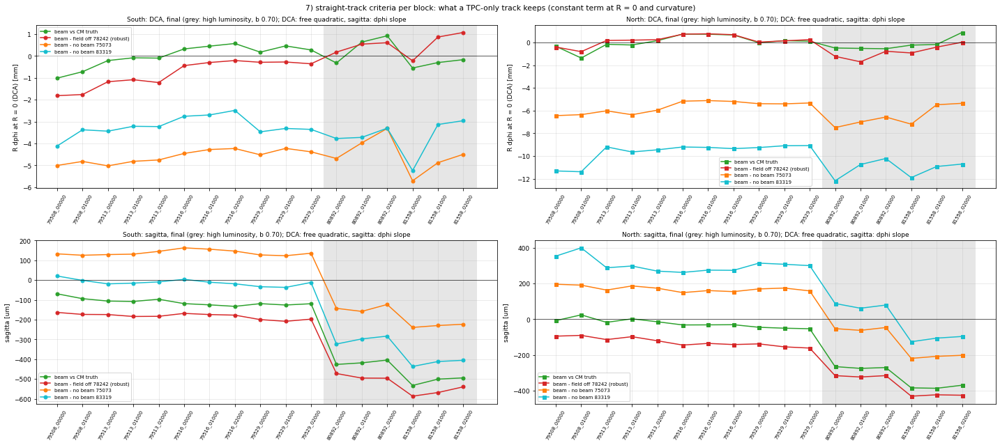

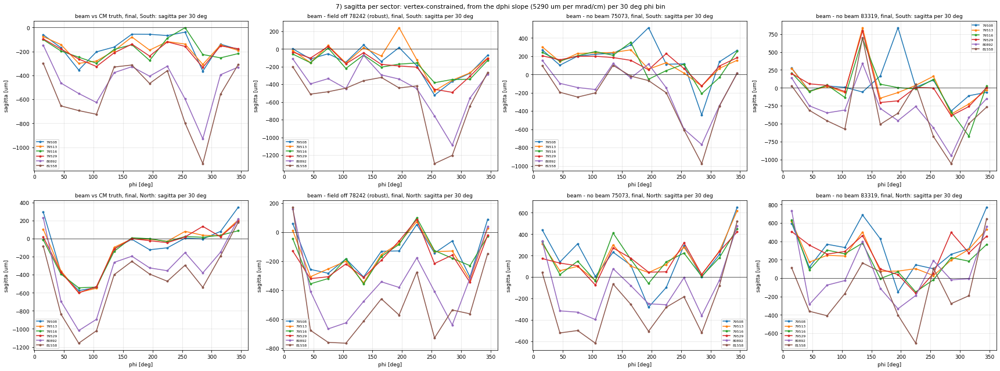

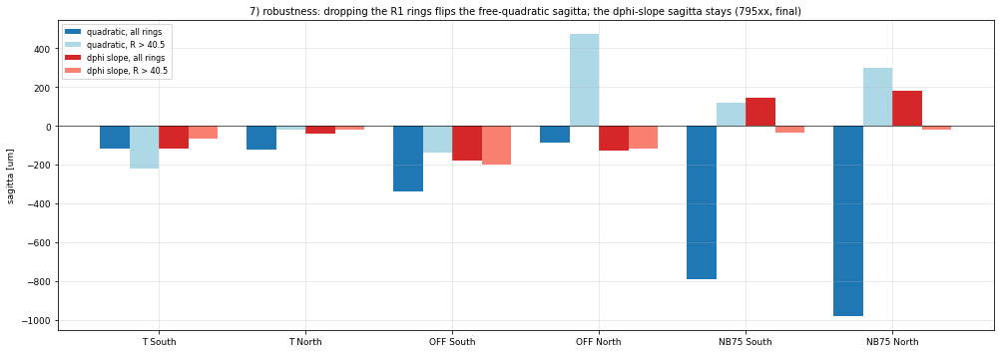

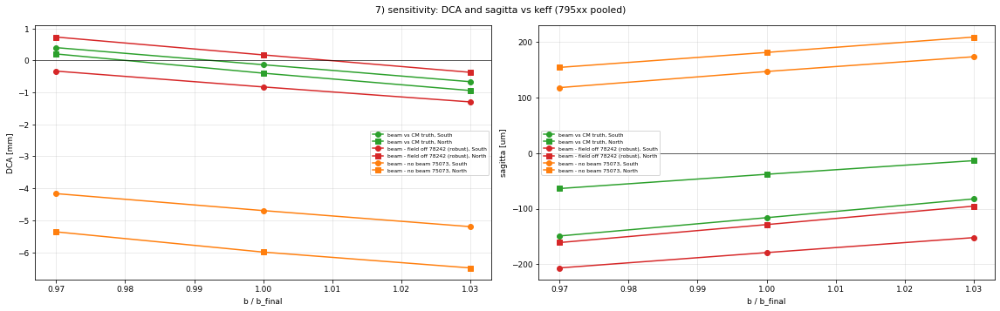

beam - no beam 75073             South: 795xx DCA -4.59 +- 0.29 mm, sag  +138 +-  13 um | high lumi DCA -4.51 mm, sag  -186 um
beam - no beam 75073             North: 795xx DCA -5.71 +- 0.50 mm, sag  +170 +-  15 um | high lumi DCA -6.52 mm, sag  -132 um
beam - no beam 83319             South: 795xx DCA -3.22 +- 0.42 mm, sag   -12 +-  15 um | high lumi DCA -3.69 mm, sag  -360 um
beam - no beam 83319             North: 795xx DCA -9.66 +- 0.81 mm, sag  +303 +-  39 um | high lumi DCA -11.12 mm, sag   -17 um
beam - field off 78242 (robust)  South: 795xx DCA -0.81 +- 0.59 mm, sag  -182 +-  13 um | high lumi DCA +0.51 mm, sag  -527 um
beam - field off 78242 (robust)  North: 795xx DCA +0.19 +- 0.45 mm, sag  -127 +-  24 um | high lumi DCA -0.83 mm, sag  -373 um
beam vs CM truth                 South: 795xx DCA +0.01 +- 0.48 mm, sag  -111 +-  17 um | high lumi DCA +0.03 mm, sag  -463 um
beam vs CM truth                 North: 795xx DCA +0.04 +- 0.57 mm, sag   -24 +-  23 um | high lumi DCA -0.18 

In [7]:
m, e, table = v.sec_criteria(); show(m)
nl = len(low)
for (k, s), val in sorted(table.items()):
    print(f"{v.CMP[k]:32s} {c.SIDES[s]:5s}: 795xx DCA {np.nanmean(val[:nl,0]):+5.2f} +- {np.nanstd(val[:nl,0]):.2f} mm, sag {np.nanmean(val[:nl,1]):+5.0f} +- {np.nanstd(val[:nl,1]):3.0f} um"
          f" | high lumi DCA {np.nanmean(val[nl:,0]):+5.2f} mm, sag {np.nanmean(val[nl:,1]):+5.0f} um")

## 8. Resolution, step by step
- **Total width:** the spread of all residuals, including the φ / R structure.
- **Local width:** the residual minus the leave-one-out median of its 10° × 3.75 cm cell, i.e. the resolution.
- **What a high-pT track sees:** a straight line per 10° φ bin is subtracted; what remains is the bias relative to a
  straight line plus the resolution.

The per-ring histograms with double-Gaussian fits for every reference, quantity (RΔφ, dR) and mode are in the deck.

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/cmplots.py:966: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(3, 4, figsize=(18, 10))


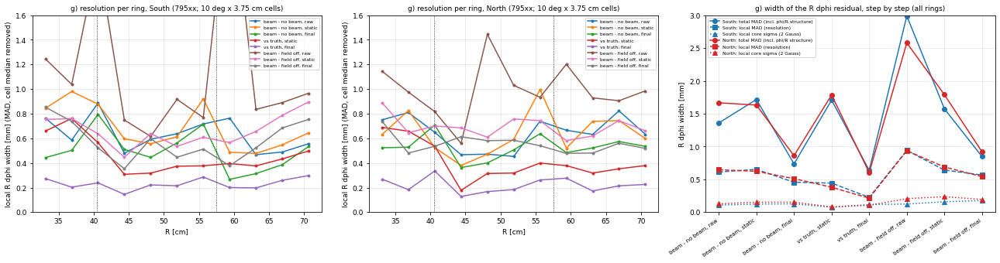

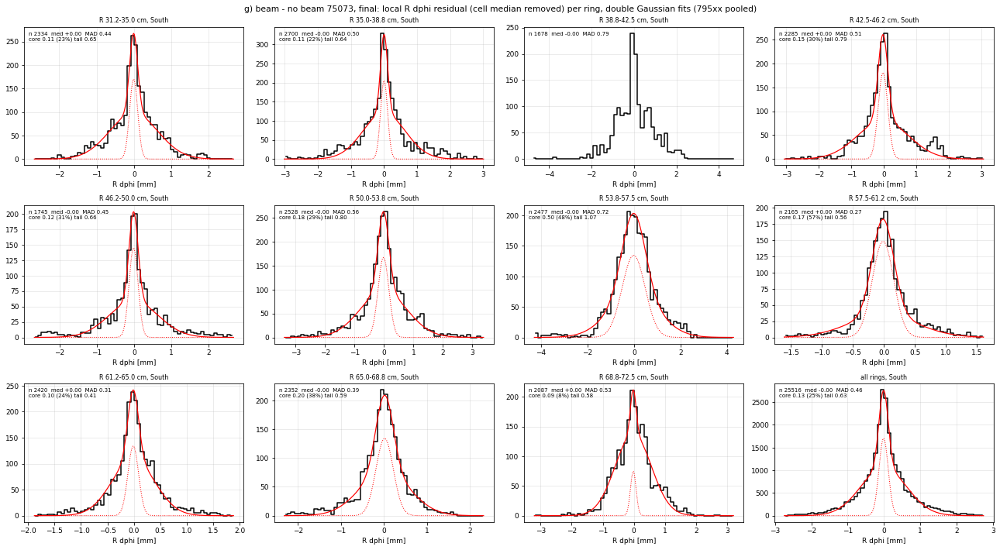

step                         South: total local     North: total local
beam - no beam, raw            1.36  0.61             1.67  0.65          
beam - no beam, static         1.72  0.65             1.63  0.62          
beam - no beam, final          0.74  0.46             0.86  0.51          
vs truth, static               1.71  0.44             1.78  0.38          
vs truth, final                0.64  0.23             0.60  0.21          
beam - field off, raw          2.99  0.94             2.58  0.94          
beam - field off, static       1.58  0.64             1.79  0.69          
beam - field off, final        0.85  0.57             0.92  0.54          


In [8]:
m, e, tab = v.sec_resolution(); show(m)
print(f"{'step':28s} {'South: total local':22s} {'North: total local'}")
for lab in dict.fromkeys(k[0] for k in tab):
    print(f"{lab:28s}" + "".join(f"  {tab[(lab, s)]['total']:5.2f} {tab[(lab, s)]['local']:5.2f}          " for s in (0, 1)))

## 9. Residual biases after the full correction, run-by-run stability
The main reference is field off; truth, field off vs truth, no beam − field off, and beam − no beam are also shown.
Then the stability over all 17 blocks.

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/cmplots.py:772: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(2, 4, figsize=(22, 8))


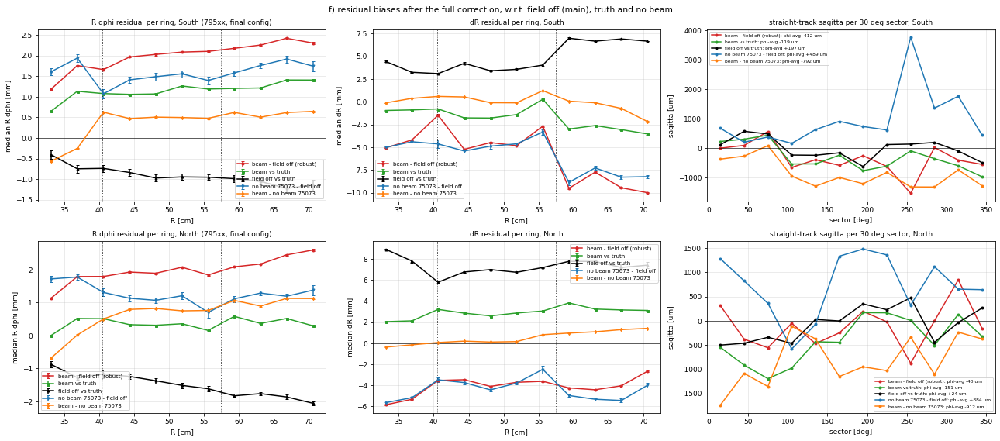

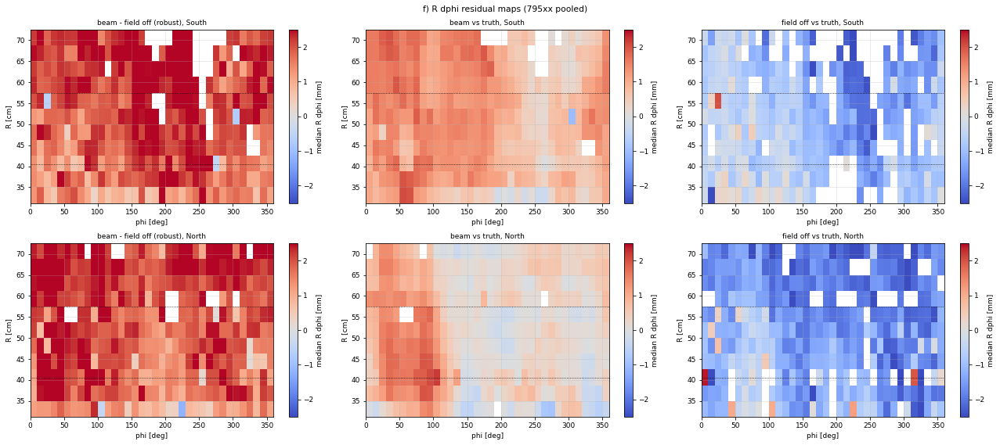

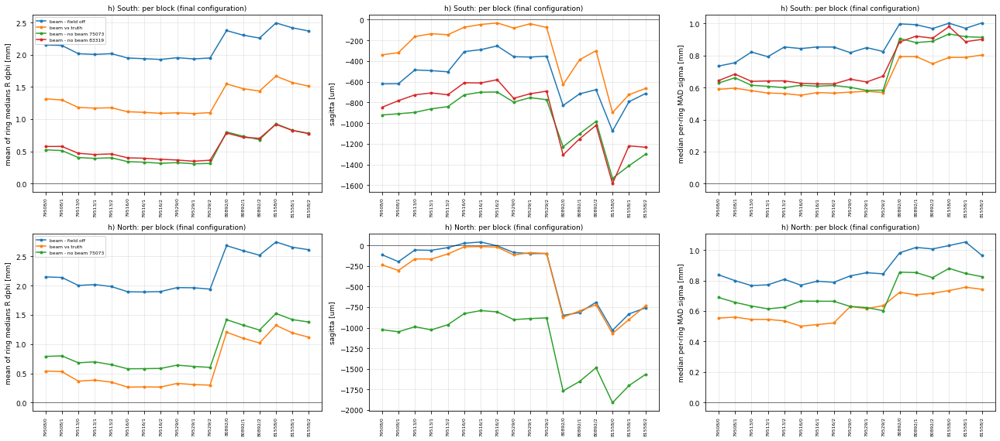

In [9]:
m, e = v.sec_stability(); show(m)

## 10. Matching QA (final configuration)
Truth matching per CM stripe row, and the cluster-to-cluster margins: distance to the nearest and second-nearest
reference cluster, mutual matches, and the radial offsets removed by the robust field-off matching.

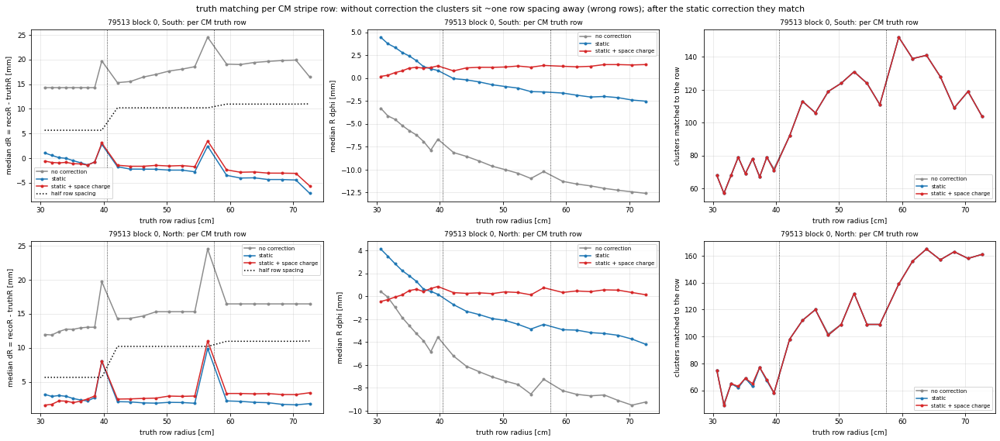

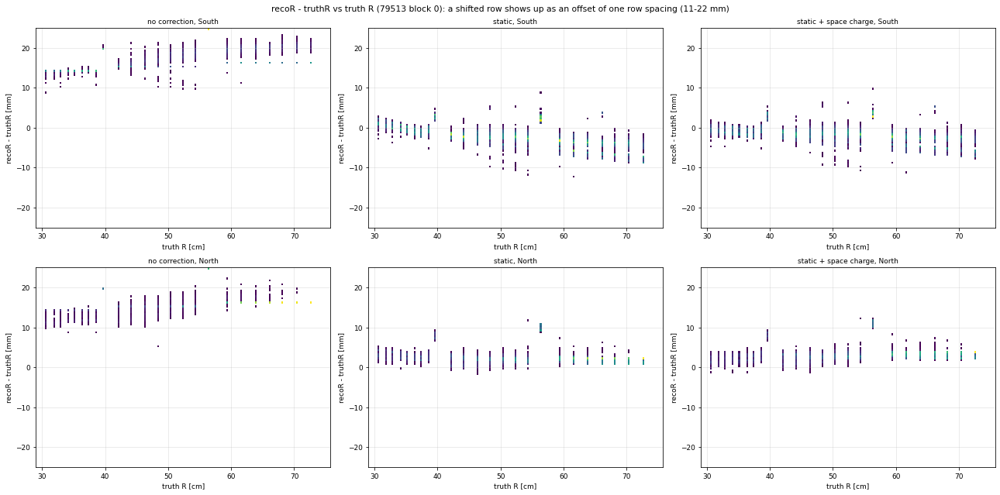

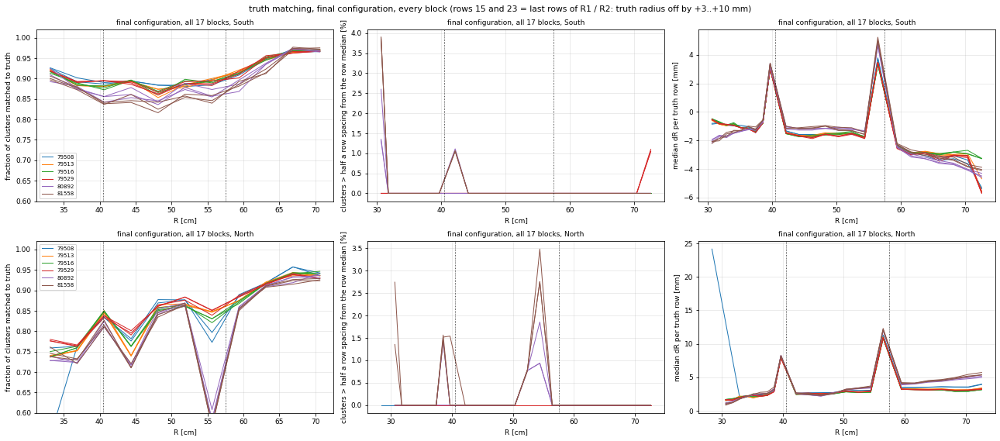

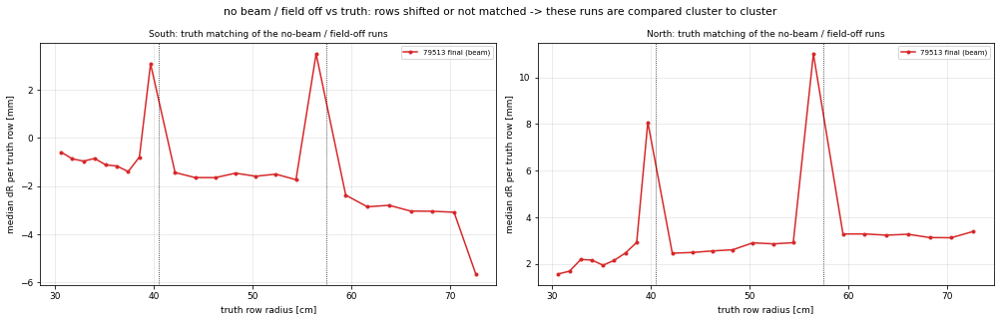

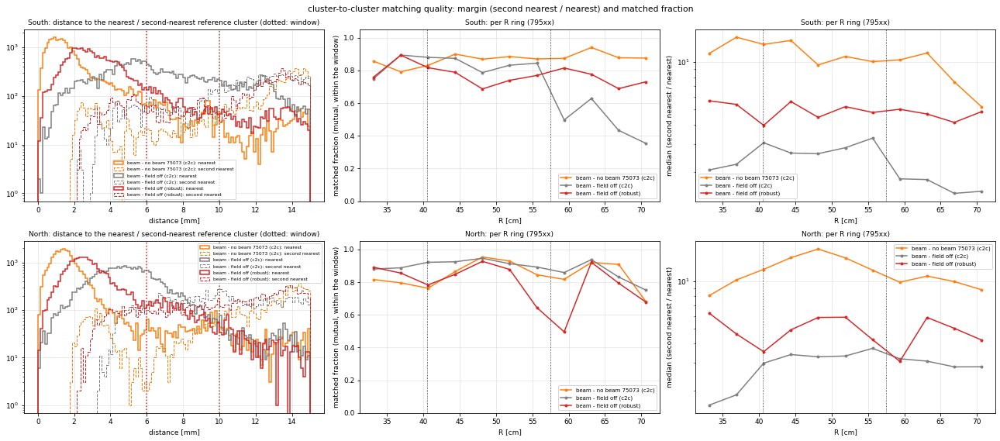

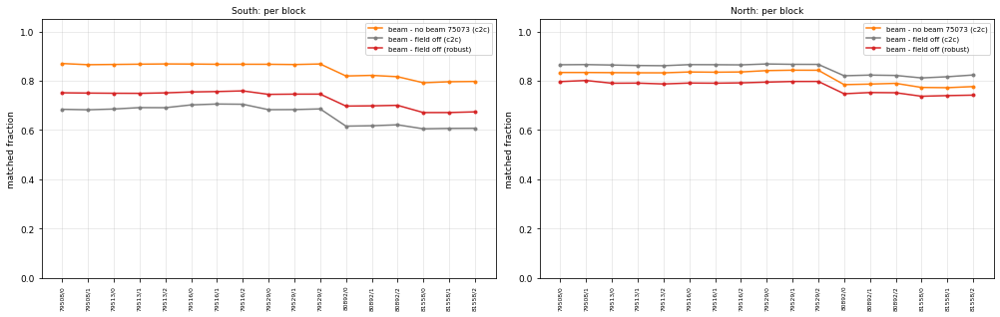

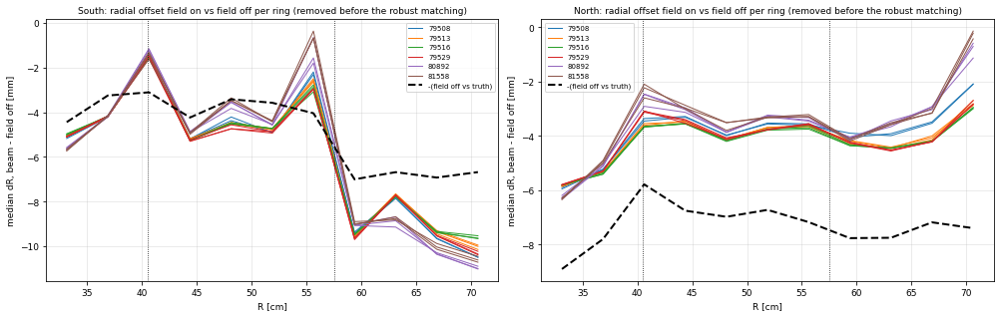

In [10]:
m, e = v.sec_matching(); show(m)

## 11. Tracks (79513)
- **keff scan with tracks:** 10000 events per point (50 × 200), α 2.0, z −40, keff S/N = b × I_side with
  b 0.66–0.84. The charge-odd rDCA crosses zero at about b = 0.73–0.74, about 9 % below the laser value.
- **Track QA per keff point** (`MakeResidualHistograms.C` + `resid_with_cluster_maps_QA_phase_space.ipynb`):
  crystal-ball rDCA0 peak vs φ and q/pT, pT ratio, residuals.

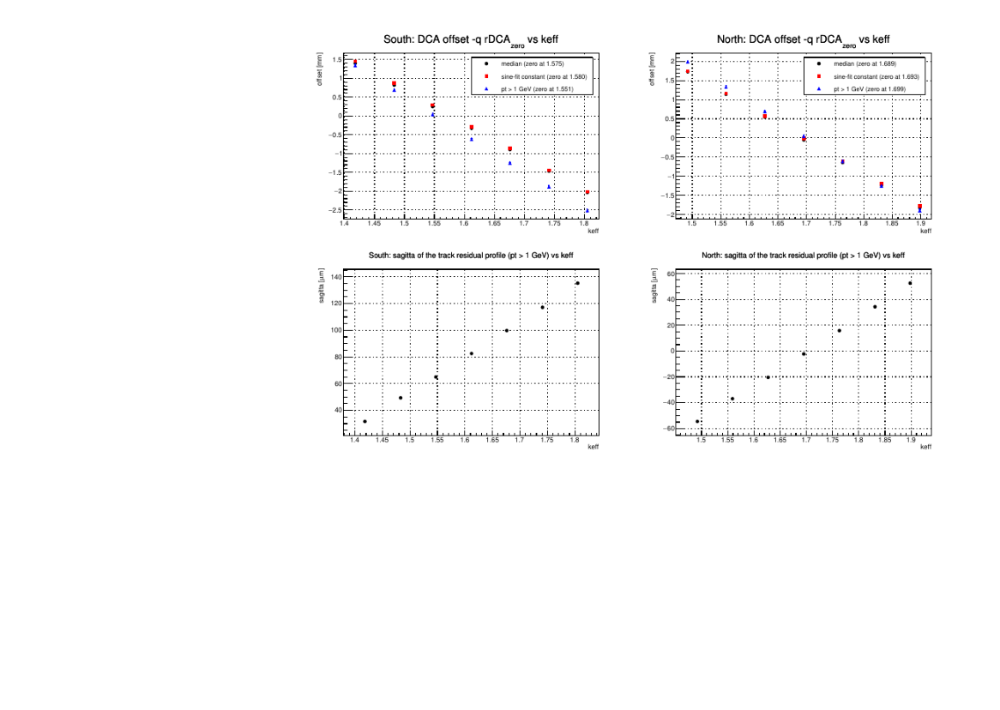

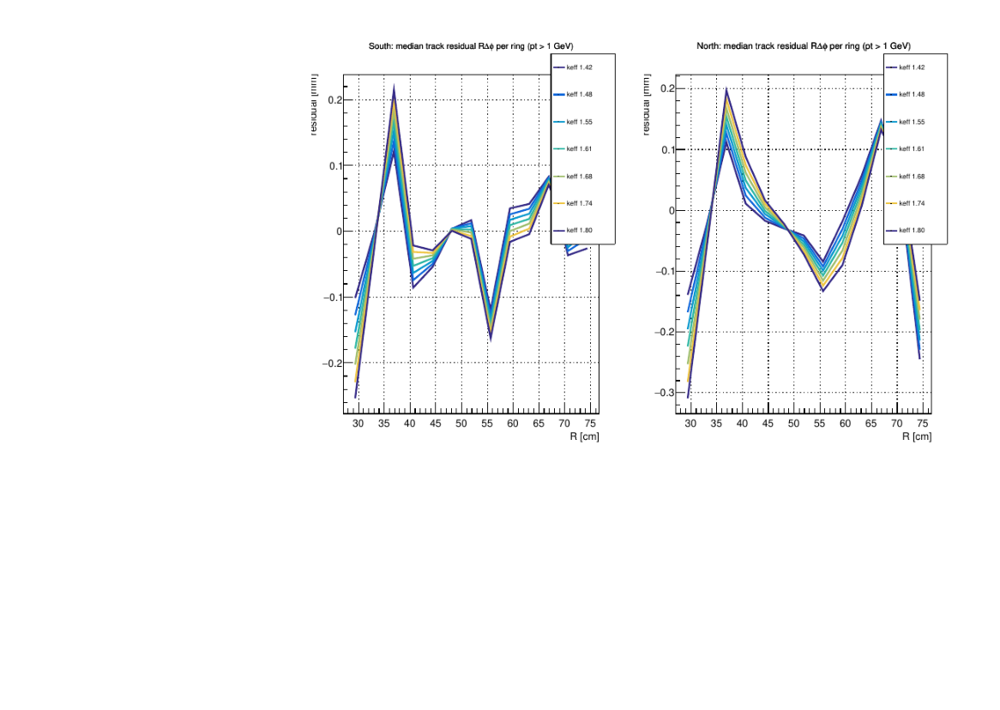

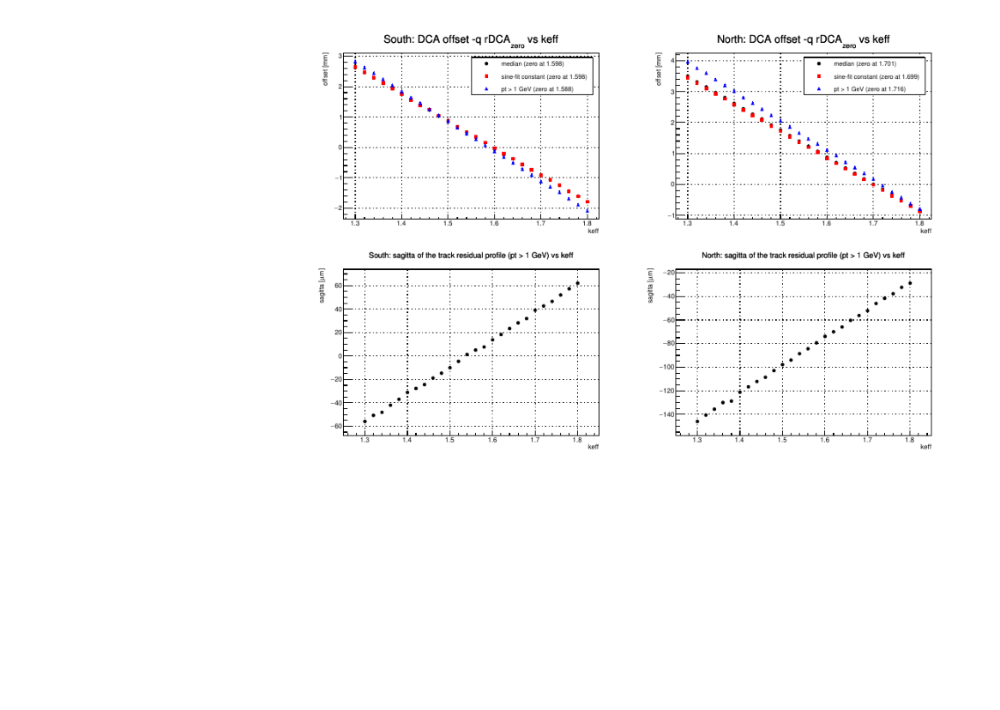

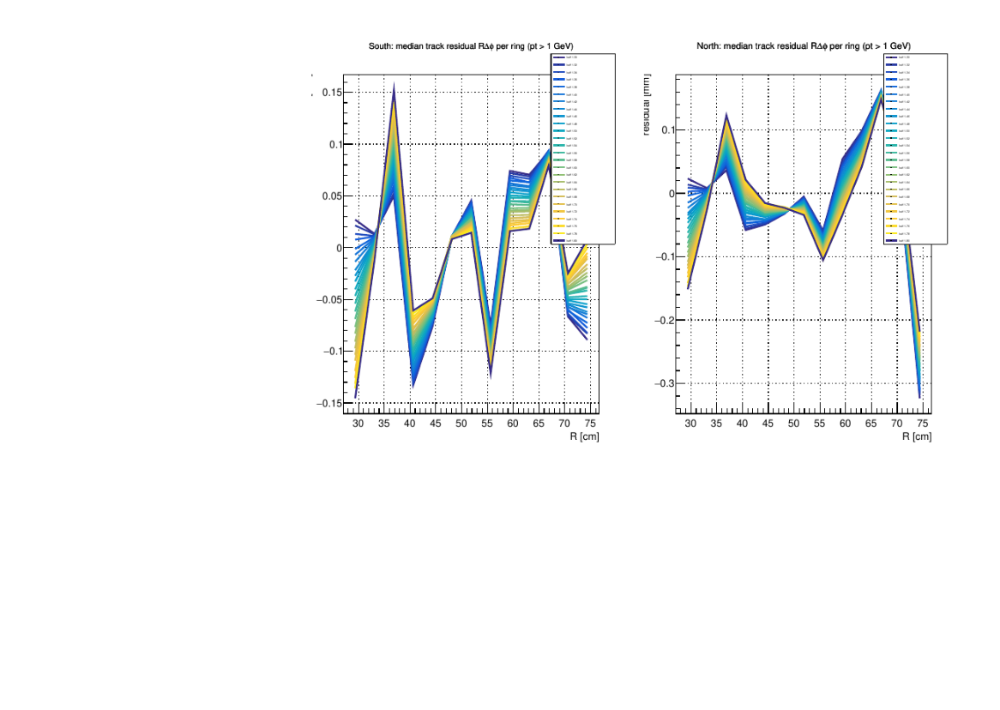

<Figure size 1152x648 with 0 Axes>

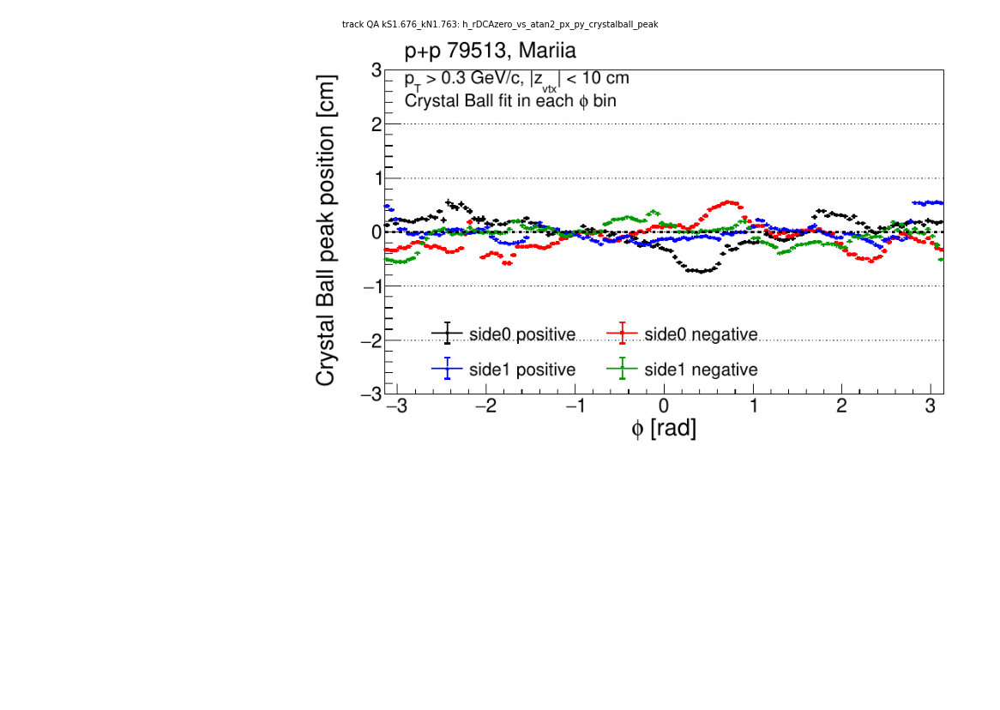

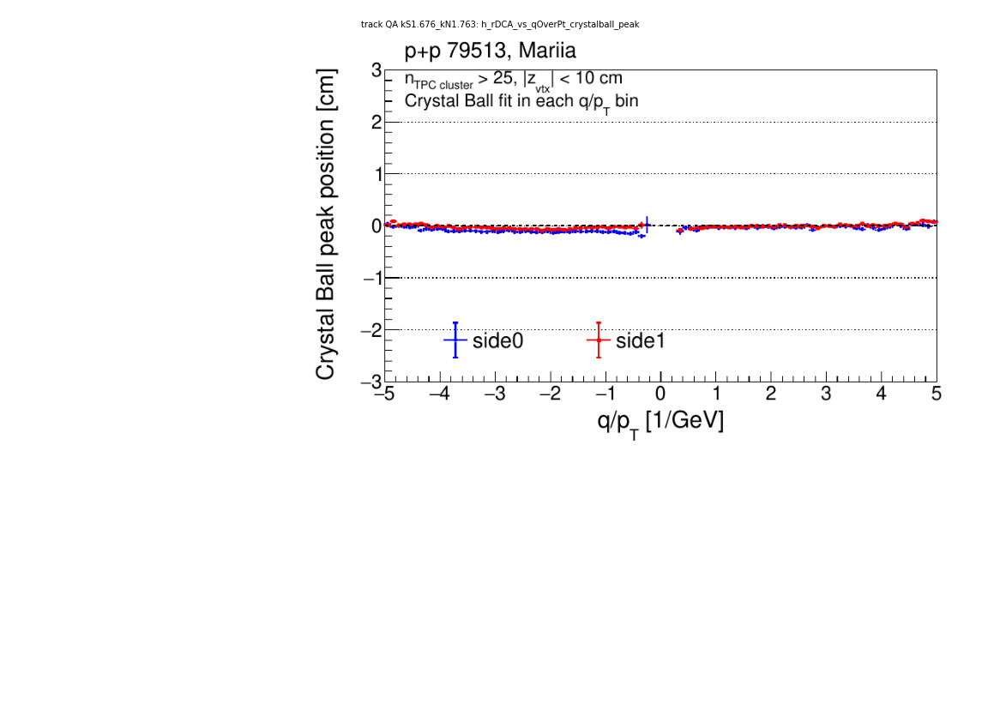

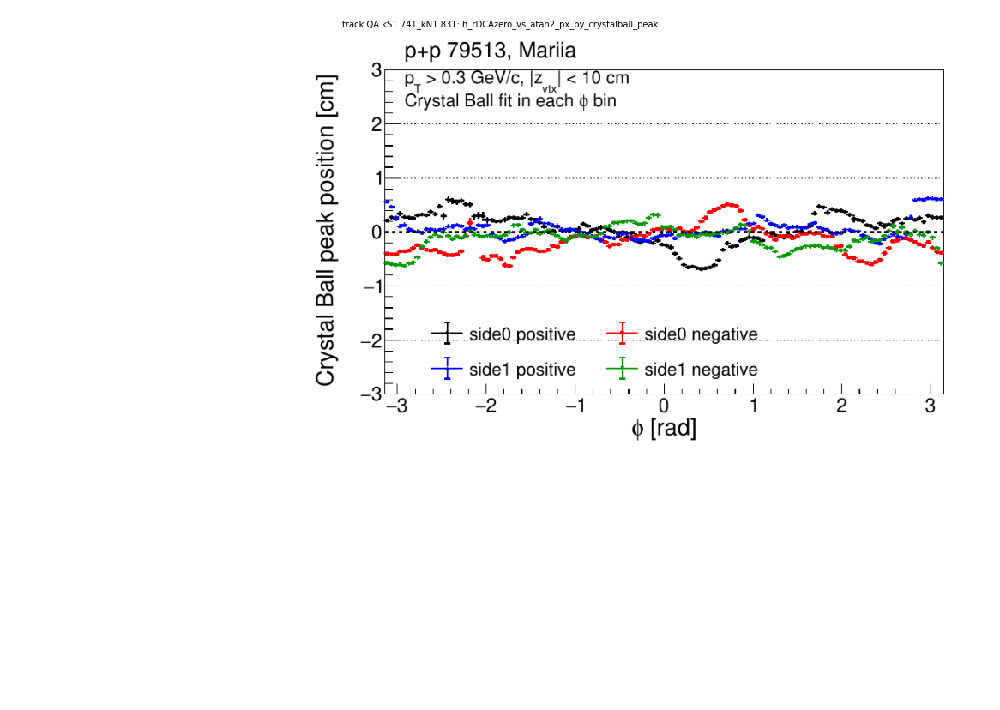

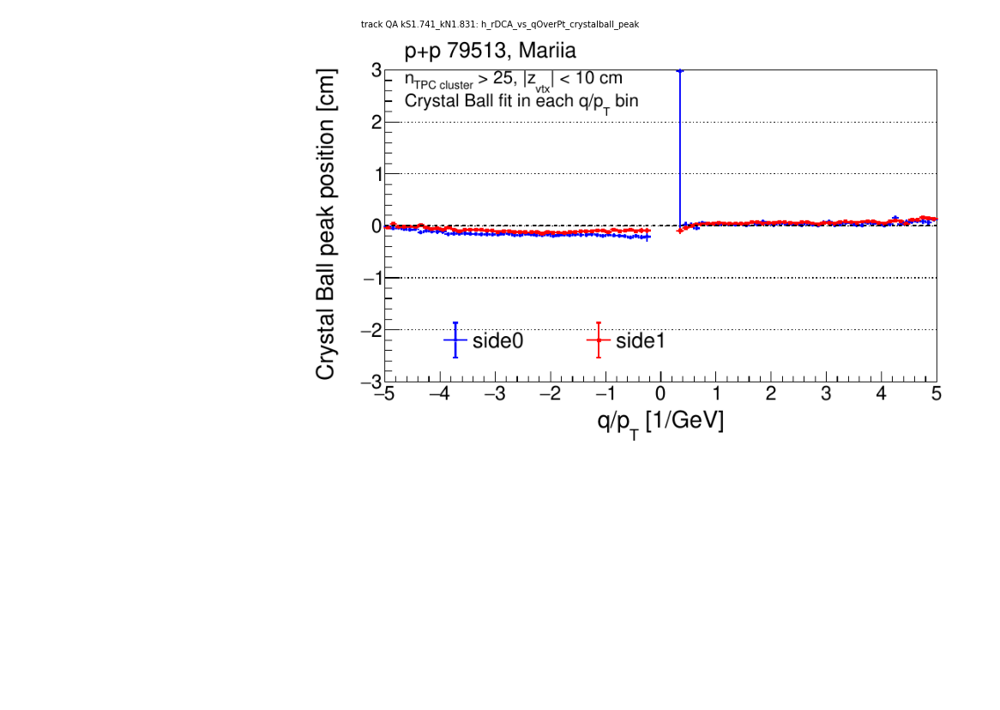

In [11]:
m, e = v.sec_tracks(); show(m)

## 12. Next: sector / module structure
The corrected beam-on − beam-off laser residual still has φ structure at the sector scale. Its keff-proportional
part is about 0.25 mm rms per unit keff, about 1 mm at high luminosity. The two no-beam references differ by a
comparable amount at fine binning, so the fit has to separate the luminosity-proportional part (a module charge fit
through linear responses; `current/TPC_PHGarfield_ModuleGainTune_v35.ipynb`).

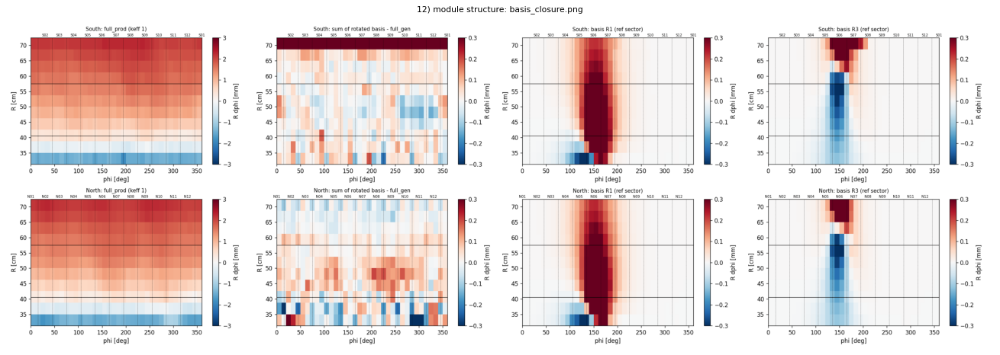

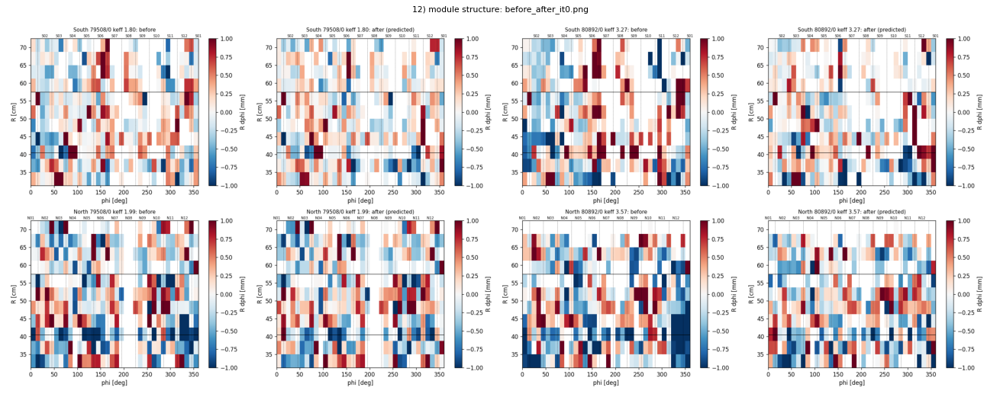

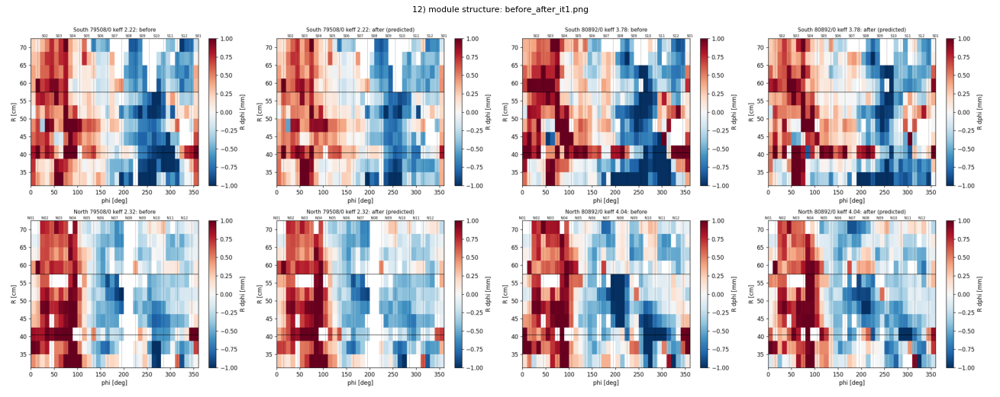

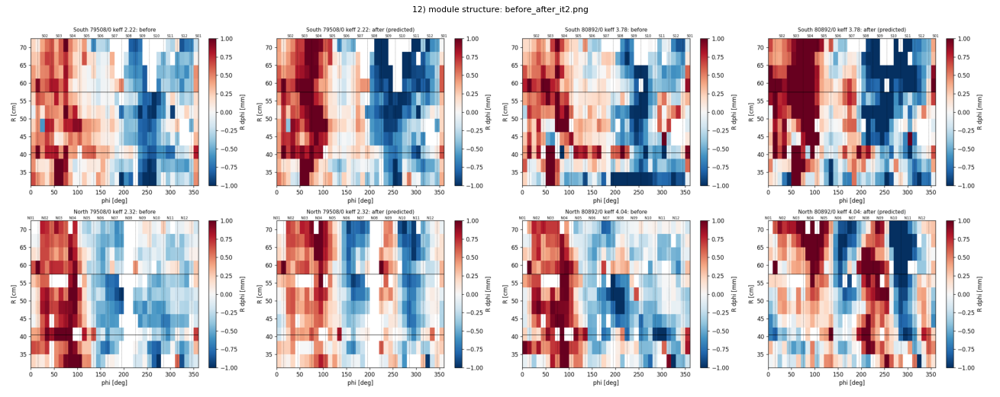

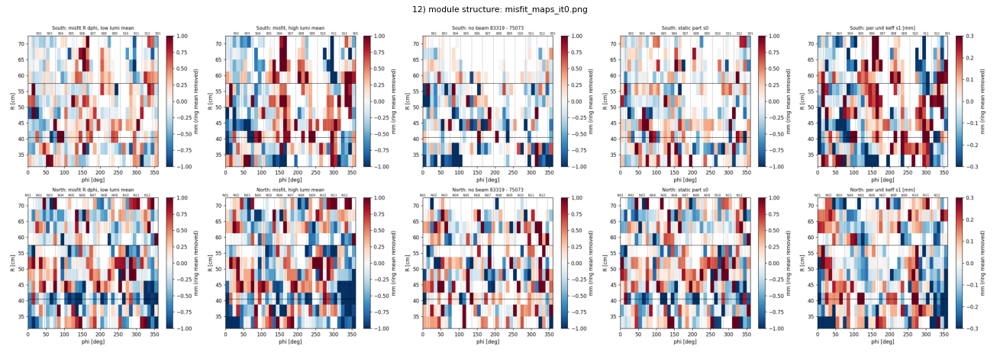

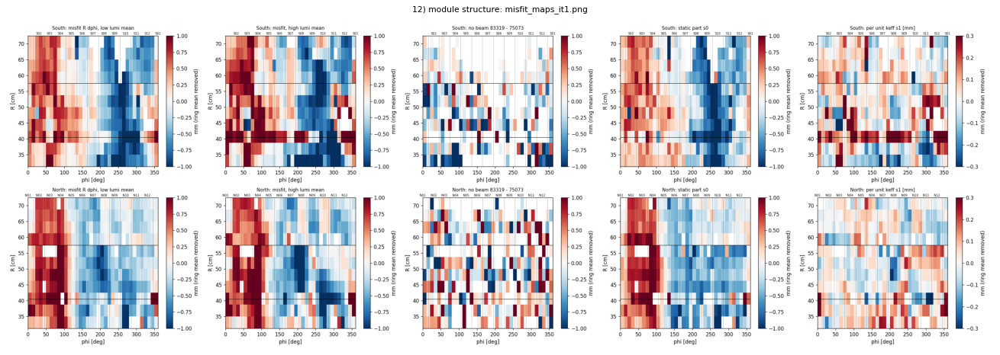

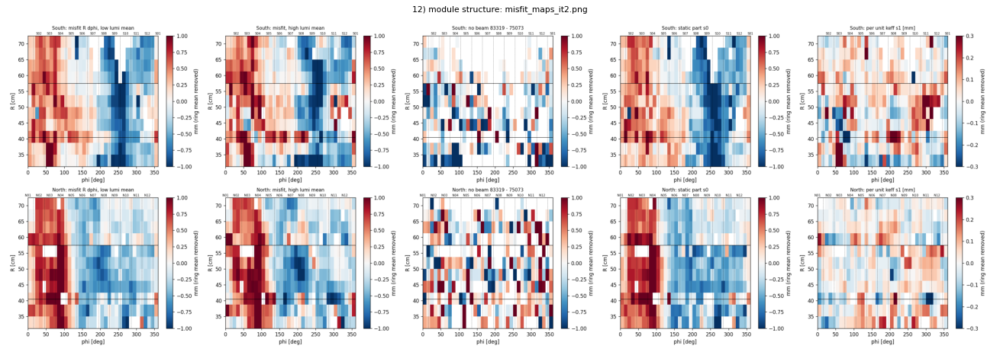

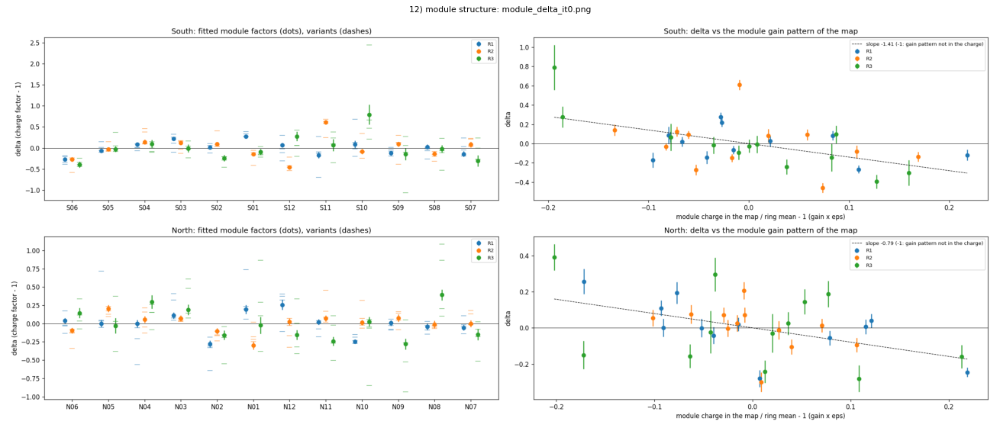

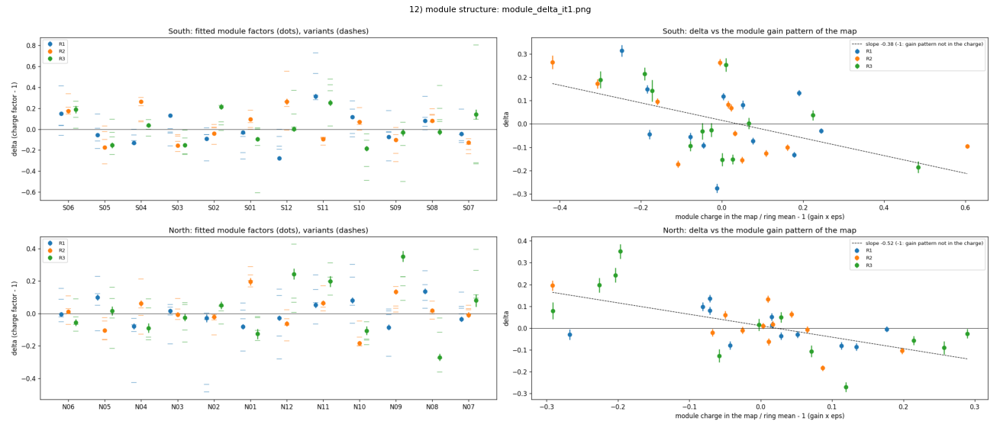

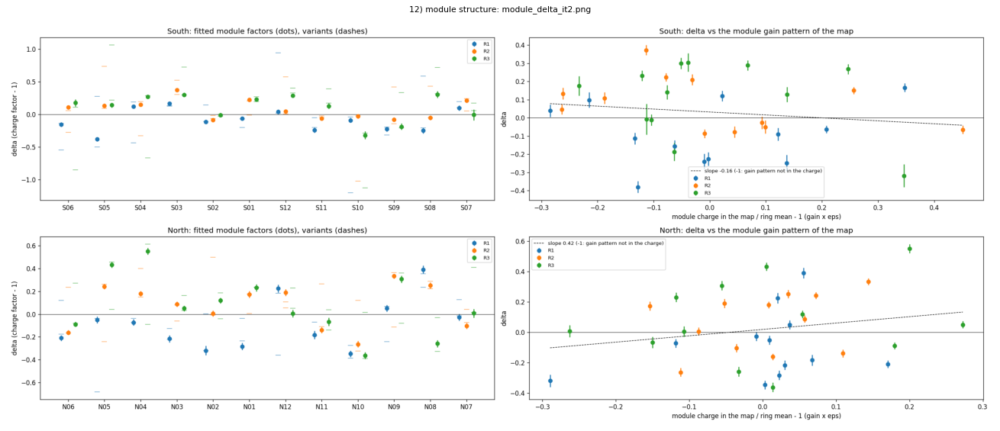

In [12]:
m, e = v.sec_module(); show(m)

## 12b. Module-tuned maps, iteration by iteration
it0 is the α 2.0 map; it1 and it2 add module charge factors fitted to the laser. All three are compared at the same keff
per block (the final b·I_side). it3 was fitted at b = 0.81, before the b update. Shown per iteration:
- the sector sagitta per run (as in section 7);
- the per-sector Δφ / dR / RΔφ profiles (as in section 6);
- the summary: sector sagitta, solid for 795xx and dashed for high lumi, with its rms and mean.

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/v2plots.py:430: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(2, 4, figsize=(24, 9))


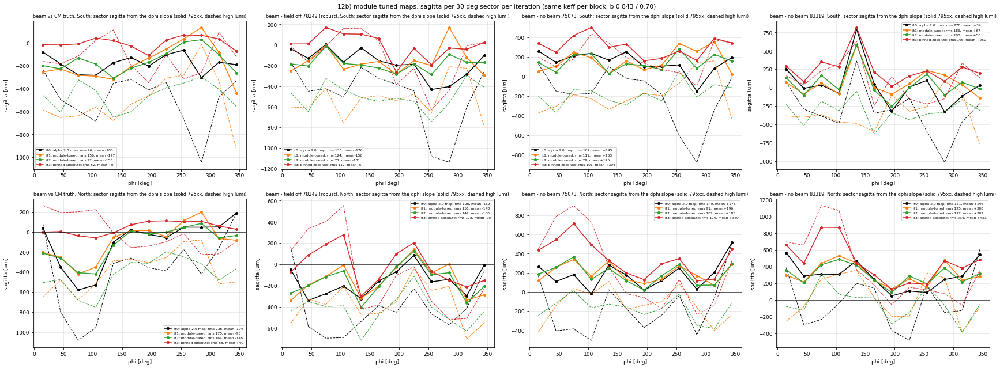

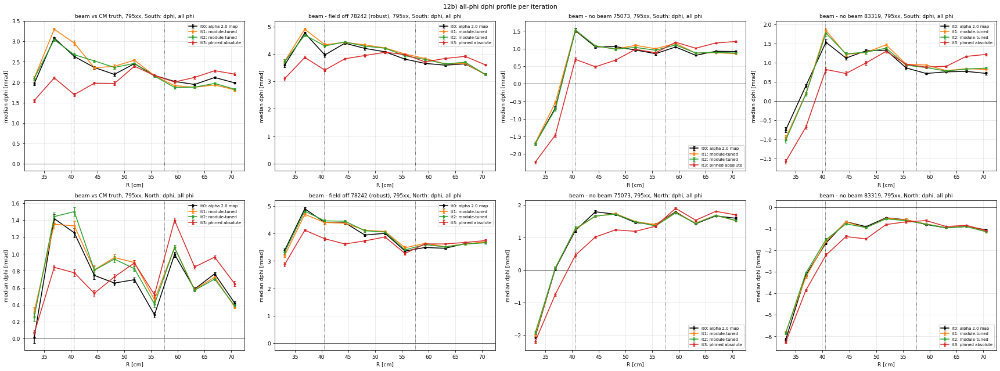

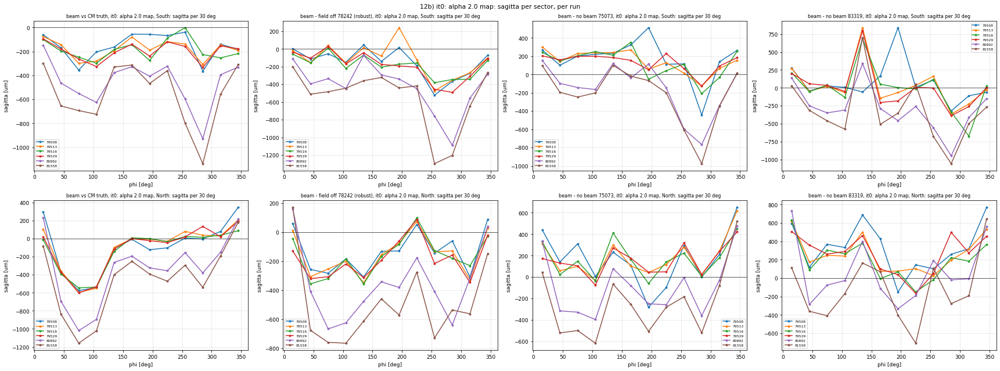

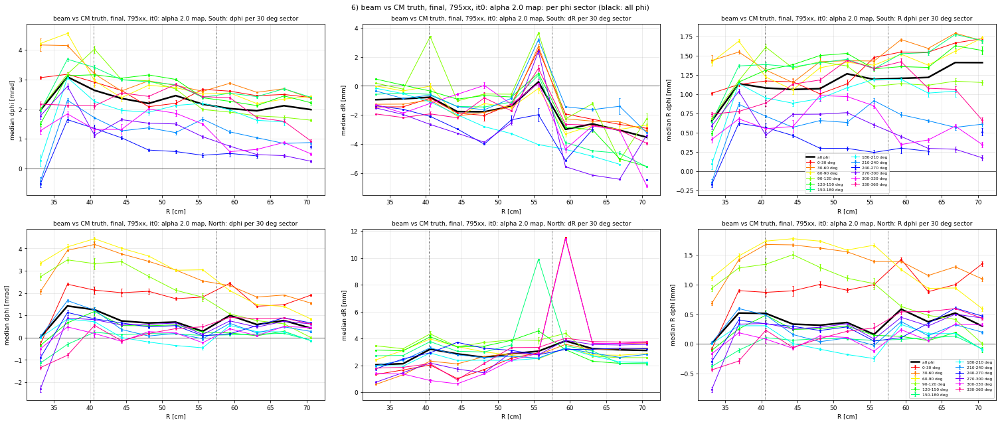

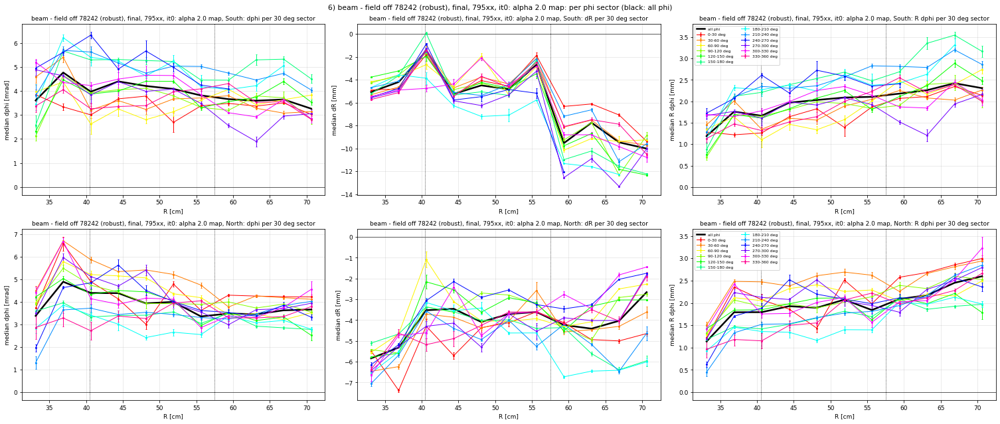

...

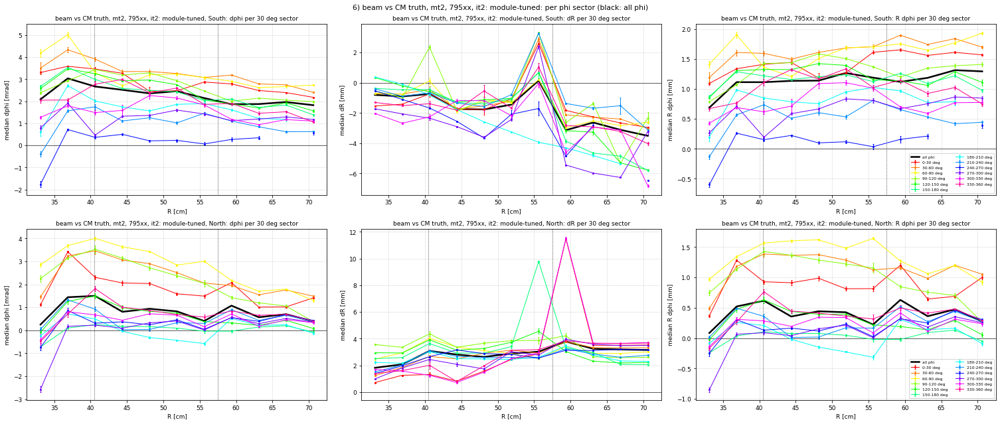

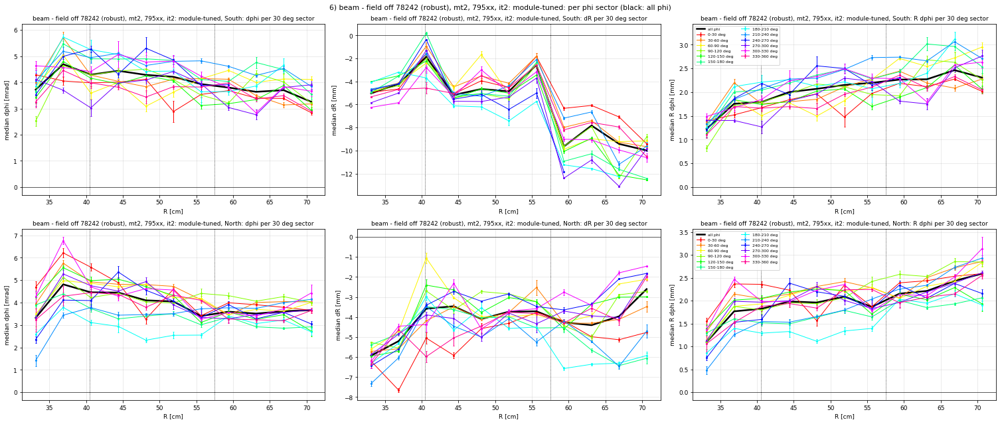

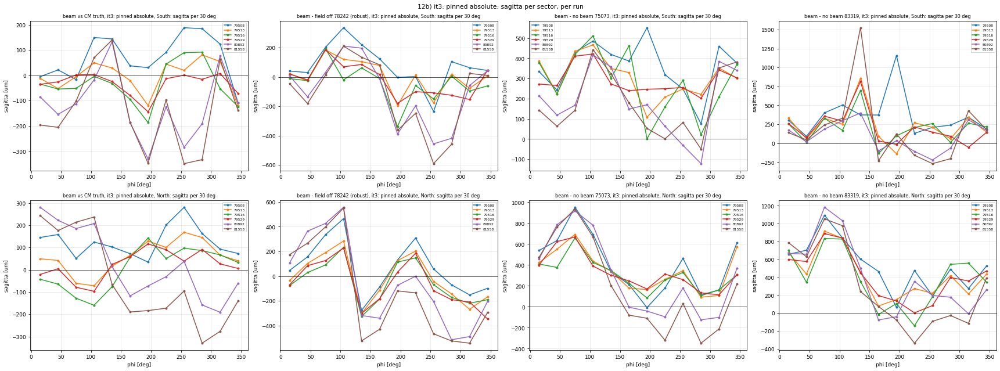

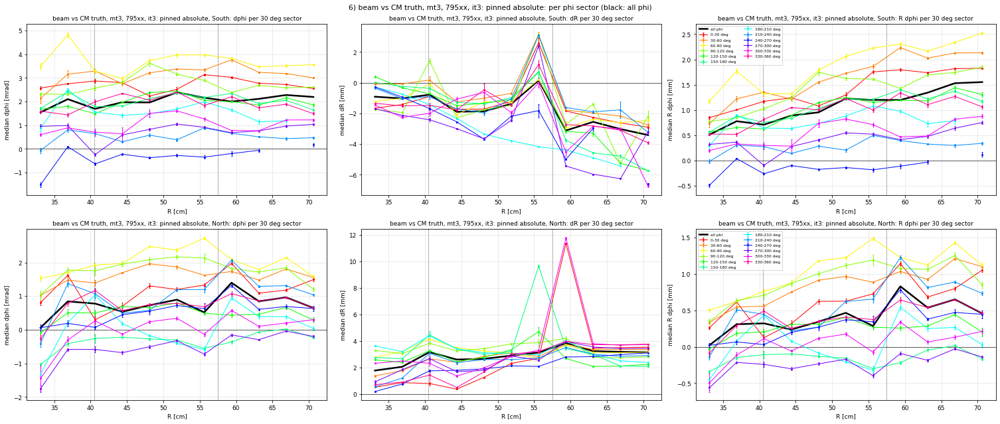

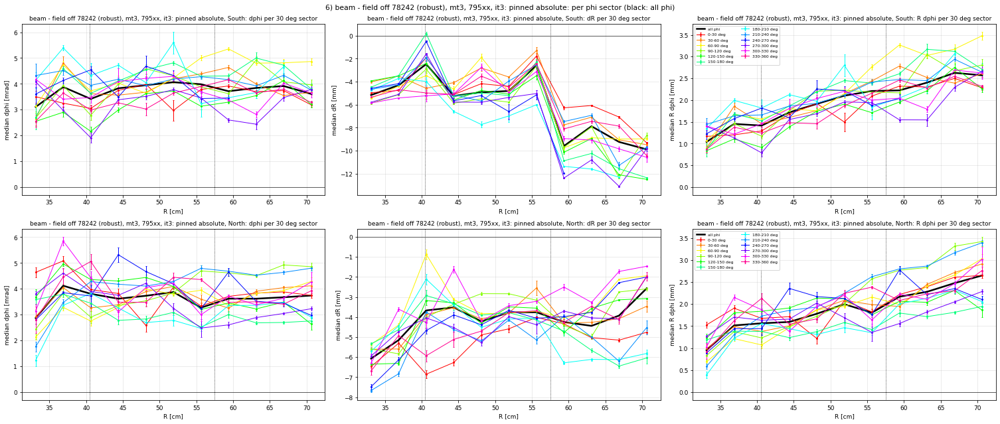

reference                        side  stage   sector-sag rms 795xx   mean  rms high   mean
beam vs CM truth                 South final                     76   -180       214   -496
beam vs CM truth                 South mt1                      156   -177       229   -500
beam vs CM truth                 South mt2                       97   -156       113   -460
beam vs CM truth                 South mt3                       52     +0       141   -131
beam vs CM truth                 North final                    236   -104       372   -387
beam vs CM truth                 North mt1                      175    -95       190   -388
beam vs CM truth                 North mt2                      164   -118       161   -423
beam vs CM truth                 North mt3                       58    +40       173     -7
beam - field off 78242 (robust)  South final                    133   -176       298   -499
beam - field off 78242 (robust)  South mt1                      124   -156      

In [13]:
m, e, rows = v.sec_iterations(); show(m)
print(f"{'reference':32s} {'side':5s} {'stage':6s} {'sector-sag rms 795xx':>21s} {'mean':>6s} {'rms high':>9s} {'mean':>6s}")
for k, s, st, r1, m1, r2, m2 in rows: print(f"{v.CMP[k]:32s} {c.SIDES[s]:5s} {st:6s} {r1:21.0f} {m1:+6.0f} {r2:9.0f} {m2:+6.0f}")

## 13. Robust sagitta, b update and the pinned map
- **13a. Which sagitta.** The free quadratic RΔφ = c0 + c1R + c2R² over 33–71 cm cannot separate the constant (DCA) from
  the curvature: they are strongly correlated, and the non-quadratic R1 structure (the bump at 33–40 cm, the module
  step) decides the split. Dropping the R1 rings flips its sign. The Δφ slope (RΔφ = c1R + c2R², a line through R = 0
  plus curvature) is what a vertex- or silicon-constrained track sees, and it is stable without R1 (13c).
- **13b. What it does to b.** The joint absolute fit (795xx, α 2.0, z −40) moves from b = 0.81 (free quadratic) to
  0.843 vs truth and 0.850 vs field off; the two references now agree. Per run, the b where the sagitta is zero and
  the b where the DCA is zero agree at low lumi (0.81–0.89). At high lumi they split (sagitta ≈ 0.82–0.89, DCA ≈ 0.70):
  the high-luminosity radial profile is flatter.
- **13d/e. The pinned map (iteration 3).** The module charges were fitted to the absolute criterion per sector vs truth
  (Δφ-slope sagitta, DCA; rotation free), with the total charge of each side fixed, so one b and the N/S GEM-current
  ratio still hold. It moves charge from R1 (−8 %) to R2 (+7 %) and R3 (+5 %) and redistributes sectors. At the final
  b, the sector-sagitta mean goes to about 0, vs truth and also vs field off (not fitted). High lumi improves too, without
  being fitted. The price is a more negative DCA (free quadratic).

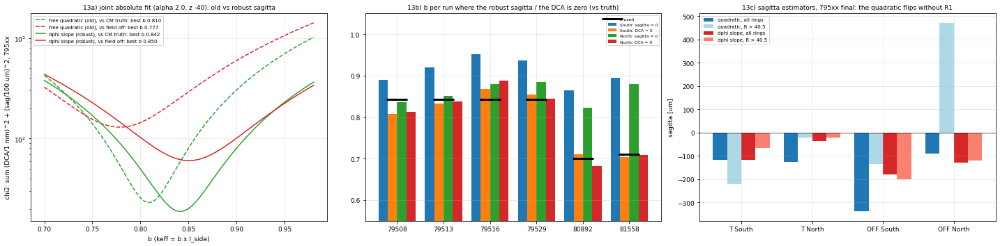

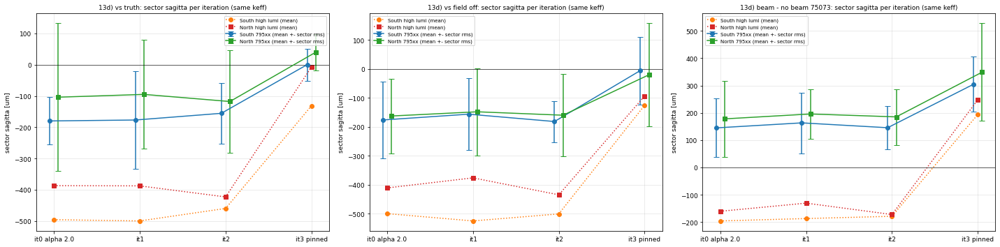

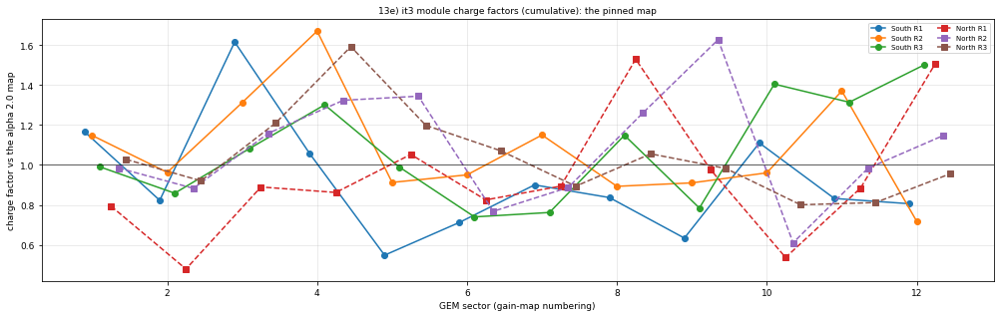

joint absolute fit, alpha 2.0, z -40, 795xx:
  free quadratic (old)   vs CM truth : b 0.8100  DCA S/N +0.48/+0.32 mm  sagitta S/N -33/-12 um
  free quadratic (old)   vs field off: b 0.7775  DCA S/N -0.03/+1.70 mm  sagitta S/N -237/+139 um
  dphi slope (robust)    vs CM truth : b 0.8425  DCA S/N -0.22/-0.45 mm  sagitta S/N -81/-22 um
  dphi slope (robust)    vs field off: b 0.8500  DCA S/N -1.55/+0.08 mm  sagitta S/N -116/-98 um
per run (vs truth): b used, b where the robust sagitta = 0, b where the DCA = 0
  79508 South: used 0.843  sagitta=0 0.889  DCA=0 0.807
  79508 North: used 0.843  sagitta=0 0.836  DCA=0 0.813
  79513 South: used 0.843  sagitta=0 0.920  DCA=0 0.833
  79513 North: used 0.843  sagitta=0 0.852  DCA=0 0.838
  79516 South: used 0.843  sagitta=0 0.952  DCA=0 0.867
  79516 North: used 0.843  sagitta=0 0.879  DCA=0 0.888
  79529 South: used 0.843  sagitta=0 0.936  DCA=0 0.855
  79529 North: used 0.843  sagitta=0 0.885  DCA=0 0.844
  80892 South: used 0.700  sagitta=0 0.8

In [14]:
m, e, info = v.sec_robust(); show(m)
print("joint absolute fit, alpha 2.0, z -40, 795xx:")
for (lab, ref), (b, dca, sag) in info['fit'].items():
    print(f"  {lab:22s} vs {ap.REFS[ref]:9s}: b {b:.4f}  DCA S/N {dca[0]:+.2f}/{dca[1]:+.2f} mm  sagitta S/N {sag[0]:+.0f}/{sag[1]:+.0f} um")
print("per run (vs truth): b used, b where the robust sagitta = 0, b where the DCA = 0")
for ref, run, s, b0, bs, bd in info['run_b']:
    if ref == 'T': print(f"  {run} {c.SIDES[s]:5s}: used {b0:.3f}  sagitta=0 {bs:.3f}  DCA=0 {bd:.3f}")
print("iterations at the same keff: sector sagitta mean / rms [um] 795xx | high lumi, DCA 795xx [mm]")
for k, s, st, m1, r1, m2, r2, d in info['iters']:
    print(f"  {v.CMP[k]:32s} {c.SIDES[s]:5s} {st:6s}: {m1:+5.0f} / {r1:3.0f} | {m2:+5.0f} / {r2:3.0f} | DCA {d:+.2f}")
print()
print(f"track test, 79513 segment 0, pinned map (it3) at the final b = {v.B_LOW:.4f}:")
print('  garfield->SetElectricFieldMap3D(".../output/sphenix_3d_ibf_field_side0_South_v35Lalpha2p0_mt3.root",')
print('                                  ".../output/sphenix_3d_ibf_field_side1_North_v35Lalpha2p0_mt3.root");')
print(f"  garfield->SetSpaceChargeScaleSide0({v.B_LOW*2.149:.3f});   // b x I_SOUTH 2.149")
print(f"  garfield->SetSpaceChargeScaleSide1({v.B_LOW*2.260:.3f});   // b x I_NORTH 2.260")
print("  (MoveTpc z -4.0, tilt 0.16 / 0.85 mrad, P/T field as before)")

## Summary
| | value | from |
|---|---|---|
| TPC tilt | rot_x 0.16, rot_y 0.85 mrad | 2b |
| TPC z | −40 mm (−30 … −50) | 2c, 5 |
| IFC | automatic (South +211 V after the change) | 2d |
| CM field | P/T corrected (TpcConditions), not 380 V/cm | 2 |
| SC map | α 2.0 (shape test 1.84 S / 1.9 N; DC extraction 2.01 / 1.92) | 3 |
| GEM current | all-module side median (SOUTH / NORTH) | 4 |
| keff | 0.843 × I_side (795xx); ≈ 0.70 × I_side at ≈ 6 µA (vertex-constrained sagitta + DCA) | 5, 13 |
| sagitta | from the Δφ slope (vertex-constrained); the free quadratic is not robust | 7, 13 |
| map | α 2.0 + module charge factors (it3, pinned): sector sagitta ≈ 0 vs truth and field off | 12b, 13 |
| tracks (79513) | charge-odd rDCA zero at b ≈ 0.73–0.74 | 11 |

**Open:**
- the laser now prefers b ≈ 0.84, while the track rDCA zero crossing preferred ≈ 0.73 (13 % apart);
- the more negative DCA with the pinned map (free-quadratic DCA, correlated with the curvature);
- the luminosity dependence of the radial profile (high-lumi b and shape);
- the sector / module structure;
- the 9 % between the laser and the tracks;
- the field-off vs truth reference difference.